# 06 — Our propagation method and independent Maxwell references

**Our method is the primary method:** $R Q^{-1}TQR$, composed at each interface, with conditional forward coupling across the rim of eligible finite lenses. The displayed comparisons cover spherical, plano-convex and biconvex dielectric bodies across the listed diameters.

| Method | What it solves | Where it applies |
|---|---|---|
| **Ours** | Homogeneous angular spectra, curved-surface transport, local Fresnel transmission and conditional two-medium rim coupling | Forward optical paths; no returning branches |
| **BEM** — boundary element method | PMCHWT coupled electric/magnetic surface currents using RWG triangular elements | One closed dielectric boundary; full interior and exterior scattering |
| **FEM** — finite element method | Vector curl-curl equation with Nédélec tetrahedral edge elements and a PML absorbing shell | One dielectric inclusion inside a finite computational domain |
| **Mie** | Analytical spherical multipole solution | Homogeneous sphere only |

PMCHWT names the Poggio–Miller–Chang–Harrington–Wu–Tsai formulation; RWG names the Rao–Wilton–Glisson basis. PML means perfectly matched layer. Stratton–Chu is a surface representation of electromagnetic fields; the BEM formulation supplies the equations for its unknown boundary data.

These first-order BEM/FEM implementations are not presumed converged. Their mesh, quadrature and domain errors are measured. **A tiny linear-system residual is not a ground-truth certificate.**

**Numerical settings:** Cartesian FFT ASM; no polar propagation or post-processing smoothing. Every FFT cell has width 24a (a = clear radius). Window width is printed separately from sampling resolution in the tables.


In [1]:
%matplotlib inline
import hashlib
import html
import platform
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import scipy
import vecdiff_general as optics
from IPython.display import HTML, Markdown, display
from matplotlib.colors import Normalize
from vecdiff_general.propagation.references import (
    DielectricBEM,
    DielectricFEM,
    MieSphere,
    SurfaceMesh,
)
from vecdiff_general.propagation.references.benchmarks import (
    compare_case,
    illumination,
)
from vecdiff_general.propagation.references.diagnostics import maxwell_residuals

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "general").is_dir())
# Solved BEM currents and FEM coefficients are stored here and reloaded on
# later runs (see DielectricBEM and DielectricFEM, cache).
import os  # noqa: E402

os.environ.setdefault("VECDIFF_BEM_CACHE", str(ROOT / ".cache" / "bem"))
os.environ.setdefault("VECDIFF_FEM_CACHE", str(ROOT / ".cache" / "fem"))
WAVELENGTH = 532e-9
METHODS = ("Ours", "BEM", "FEM", "Mie")
started = perf_counter()
cases = []
extra_rows = []
plt.rcParams.update({"figure.dpi": 150, "axes.grid": False})
print(f"Vacuum wavelength: {WAVELENGTH * 1e9:g} nm; n_out = 1; n_in = 1.5")
print(
    f"Python {platform.python_version()}, NumPy {np.__version__}, SciPy {scipy.__version__}"
)


def show(rows, columns):
    # Inherit foreground/background from Jupyter or VS Code, including dark mode.
    parts = [
        '<div style="max-width:100%;overflow-x:auto;color:inherit">',
        '<table style="border-collapse:collapse;font-size:13px;color:inherit;background:transparent">',
        '<thead><tr style="background:rgba(127,127,127,.18);color:inherit">',
    ]
    parts += [
        f'<th style="padding:9px;text-align:left;color:inherit;border-bottom:2px solid rgba(127,127,127,.65)">{html.escape(label)}</th>'
        for _, label in columns
    ]
    parts.append("</tr></thead><tbody>")
    previous = object()
    group = 0
    for row in rows:
        diameter = row.get("diameter_lambda")
        if diameter != previous:
            group += 1
            previous = diameter
        color = "rgba(127,127,127,.10)" if group % 2 else "transparent"
        parts.append(f'<tr style="background:{color};color:inherit">')
        for key, _ in columns:
            value = row.get(key)
            if value is None:
                text = "—"
            elif isinstance(value, (float, np.floating)):
                text = (
                    f"{value:g}"
                    if key in ("diameter_lambda", "resolution")
                    else f"{value:.3e}"
                )
            else:
                text = str(value)
            parts.append(
                f'<td style="padding:9px;color:inherit;background:transparent;border-bottom:1px solid rgba(127,127,127,.3);max-width:32ch;white-space:normal">{html.escape(text)}</td>'
            )
        parts.append("</tr>")
    parts.append("</tbody></table></div>")
    display(HTML("".join(parts)))


def finest_rows(group):
    rows = []
    for case in group:
        for method in METHODS:
            available = [r for r in case["rows"] if r["method"] == method]
            if not available:
                continue
            measured = [r for r in available if "setup_seconds" in r]
            selected = dict(measured[-1] if measured else available[-1])
            if measured and available[-1] is not measured[-1]:
                selected["status"] += "; finer mesh exceeded budget"
            rows.append(selected)
    return rows


def report(group):
    rows = finest_rows(group)
    display(Markdown("### Field comparison and numerical refinement"))
    show(
        rows,
        [
            ("diameter_lambda", "D / λ₀"),
            ("method", "Method"),
            ("resolution", "Resolution¹"),
            ("window_apertures", "FFT width / clear radius"),
            ("field_gap", "Relative E gap²"),
            ("mesh_change", "Refinement change"),
            ("status", "Interpretation"),
        ],
    )
    display(Markdown("### Boundary conditions and energy"))
    show(
        rows,
        [
            ("diameter_lambda", "D / λ₀"),
            ("method", "Method"),
            ("boundary_scope", "Boundary tested"),
            ("tangential_E", "Tangential E"),
            ("tangential_H", "Tangential H"),
            ("normal_D", "Normal D"),
            ("normal_B", "Normal B"),
            ("flux_error", "Flux residual"),
            ("flux_scope", "Flux definition"),
        ],
    )
    display(Markdown("### Equations and execution time"))
    show(
        rows,
        [
            ("diameter_lambda", "D / λ₀"),
            ("method", "Method"),
            ("maxwell_max", "Strong PDE residual³"),
            ("algebraic_residual", "Weak solve residual"),
            ("mesh_seconds", "Mesh [s]"),
            ("setup_seconds", "Build + solve [s]"),
            ("evaluation_seconds", "Four probes [s]"),
        ],
    )
    display(Markdown("### All refinement runs (same geometry; parameters grouped)"))
    show(
        [r for c in group for r in c["rows"]],
        [
            ("diameter_lambda", "D / λ₀"),
            ("method", "Method"),
            ("resolution", "Resolution¹"),
            ("window_apertures", "FFT width / clear radius"),
            ("mesh_change", "Refinement change"),
            ("setup_seconds", "Build + solve [s]"),
            ("status", "Interpretation"),
        ],
    )


def geometry_view(case):
    radius = case["diameter_lambda"] * WAVELENGTH / 2
    fig, ax = plt.subplots(figsize=(7, 3))
    if case["geometry"] == "sphere":
        t = np.linspace(0, 2 * np.pi, 300)
        ax.fill(
            radius * np.cos(t) / WAVELENGTH,
            radius * np.sin(t) / WAVELENGTH,
            color="#c6ddef",
        )
        aperture = case["system"].apertures[0]
        ax.axvline(
            aperture / WAVELENGTH,
            color="tab:orange",
            ls="--",
            label="Our central chart",
        )
        ax.axvline(-aperture / WAVELENGTH, color="tab:orange", ls="--")
    else:
        x = np.linspace(-radius, radius, 300)
        xy = np.column_stack((x, np.zeros_like(x)))
        volume = case["volume"]
        front = volume.front.height(xy) + volume.front.frame.origin[2]
        back = volume.back.height(xy) + volume.back.frame.origin[2]
        ax.fill_between(
            x / WAVELENGTH,
            front / WAVELENGTH,
            back / WAVELENGTH,
            color="#c6ddef",
            label="Closed dielectric, including rim",
        )
    ax.scatter(
        case["probes"].points[:, 0] / WAVELENGTH,
        case["probes"].points[:, 2] / WAVELENGTH,
        color="black",
        s=20,
        label="Comparison probes (projected)",
    )
    ax.set(
        xlabel="x / λ₀",
        ylabel="z / λ₀",
        title=f"{case['geometry']}, D / λ₀ = {case['diameter_lambda']:g}; n = 1.5",
    )
    ax.set_aspect("equal")
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    plt.show()


def paraxial_plane(case):
    """Back focal plane from the two paraxial refraction matrices; guide only."""
    front, back = [i.surface for i in case["system"].interfaces]
    n = case["interior"].material.n
    d = back.frame.origin[2] - front.frame.origin[2]
    power_front = 0 if isinstance(front, optics.Plane) else (n - 1) / front.radius
    power_back = (1 - n) / back.radius
    power = power_front + power_back - d / n * power_front * power_back
    return back.frame.origin[2] + (1 - d / n * power_front) / power


def draw_body(ax, case):
    radius = case["diameter_lambda"] * WAVELENGTH / 2
    if case["geometry"] == "sphere":
        phi = np.linspace(0, 2 * np.pi, 200)
        ax.fill(
            radius * np.sin(phi) / WAVELENGTH,
            radius * np.cos(phi) / WAVELENGTH,
            color="#777777",
            ec="black",
            lw=0.7,
            zorder=5,
        )
    else:
        x = np.linspace(-radius, radius, 200)
        xy = np.column_stack((x, np.zeros_like(x)))
        front, back = case["volume"].front, case["volume"].back
        zf = front.height(xy) + front.frame.origin[2]
        zb = back.height(xy) + back.frame.origin[2]
        ax.fill(
            np.r_[zf, zb[::-1]] / WAVELENGTH,
            np.r_[x, x[::-1]] / WAVELENGTH,
            color="#777777",
            ec="black",
            lw=0.7,
            zorder=5,
        )


def evaluated_fields(case, names, grid):
    """Retain exact BEM samples so style changes can reuse numerical data."""
    values = {}
    for name in names:
        solution = case["solutions"][name]
        if name != "BEM":
            values[name] = solution.evaluate(grid)
            continue
        digest = hashlib.sha256()
        library = ROOT / "general/src/vecdiff_general"
        for path in sorted(library.rglob("*")):
            if path.suffix in (".py", ".f90", ".so"):
                digest.update(str(path.relative_to(library)).encode())
                digest.update(path.read_bytes())
        for array in (
            grid.points,
            solution.mesh.vertices,
            solution.mesh.triangles,
            solution.coefficients,
            solution._q,
            solution._w,
            solution.source.wavevectors,
            solution.source.amplitudes,
            solution.source.origin,
            np.array(
                [
                    solution.wavelength0,
                    solution.interior.material.n,
                    solution.exterior.material.n,
                ]
            ),
        ):
            array = np.ascontiguousarray(array)
            digest.update(str((array.shape, array.dtype)).encode())
            digest.update(array.tobytes())
        folder = ROOT / ".cache/reference_fields"
        folder.mkdir(parents=True, exist_ok=True)
        path = folder / f"{digest.hexdigest()}.npz"
        if path.exists():
            with np.load(path, allow_pickle=False) as stored:
                values[name] = optics.ElectromagneticField(
                    optics.ElectricField(grid, solution.wavelength0, stored["E"]),
                    stored["H"],
                )
        else:
            field = solution.evaluate(grid)
            np.savez_compressed(path, E=field.electric.values, H=field.magnetic)
            values[name] = field
    return values


def field_view(case):
    """Meridional and common focal-plane maps, with notebook-05 conventions."""
    radius = case["diameter_lambda"] * WAVELENGTH / 2
    entry_z = case["system"].interfaces[0].surface.frame.origin[2]
    exit_z = case["system"].interfaces[-1].surface.frame.origin[2]
    guide = paraxial_plane(case)
    end = max(exit_z + 3 * WAVELENGTH, exit_z + 1.5 * (guide - exit_z))
    extent = max(
        1.3 * radius, 0.8 * WAVELENGTH * (guide - exit_z) / (2 * radius), WAVELENGTH
    )
    z = np.linspace(exit_z + 0.08 * WAVELENGTH, end, 321)
    x = np.linspace(-extent, extent, 161)
    zz, xx = np.meshgrid(z, x)
    grid = optics.PointGrid(np.stack((xx, np.zeros_like(xx), zz), -1))
    # An unconverged FEM reconstruction is documented below as a mesh diagnostic.
    names = [name for name in METHODS if name in case["solutions"] and name != "FEM"]
    fields = evaluated_fields(case, names, grid)
    quantities = (
        lambda field: field.electric.norm2(),
        lambda field: abs(field.electric.Ez) ** 2,
    )
    titles = ("|E|²", "|E_z|²")
    unit = 1e-6
    fig, axes = plt.subplots(
        len(names),
        2,
        figsize=(12, 3.7 * len(names)),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    for column, (quantity, title) in enumerate(zip(quantities, titles)):
        values = {name: quantity(fields[name]) for name in names}
        for row, name in enumerate(names):
            maximum = float(values[name].max())
            ax = axes[row, column]
            im = ax.pcolormesh(
                z / unit,
                x / unit,
                values[name],
                cmap="hot",
                shading="nearest",
                norm=Normalize(0, maximum),
            )
            ax.axvline(guide / unit, color="cyan", ls="--", lw=0.9)
            # draw_body uses wavelength coordinates; transform the outline to µm.
            before = len(ax.patches)
            draw_body(ax, case)
            for patch in ax.patches[before:]:
                patch.set_xy(patch.get_xy() * WAVELENGTH / unit)
            ax.set(
                xlabel="z (µm)",
                ylabel="x (µm)",
                title=f"{name + ' (Cartesian ASM)' if name == 'Ours' else name}: {title}",
                xlim=((entry_z - 0.12 * WAVELENGTH) / unit, end / unit),
                ylim=(-extent / unit, extent / unit),
            )
            if case["geometry"] == "sphere":
                ax.set_aspect("equal", adjustable="box")
                if name == "Ours":
                    aperture = case["system"].apertures[0]
                    cap_x = np.linspace(-aperture, aperture, 101)
                    cap_xy = np.column_stack((cap_x, np.zeros_like(cap_x)))
                    for interface in case["system"].interfaces:
                        surface = interface.surface
                        cap_z = surface.height(cap_xy) + surface.frame.origin[2]
                        ax.plot(
                            cap_z / unit,
                            cap_x / unit,
                            color="tab:orange",
                            lw=2,
                            zorder=6,
                        )
            fig.colorbar(im, ax=ax, label="V²/m²")
    fig.suptitle(
        f"Meridional plane y = 0 — {case['geometry']}, D = {case['diameter_lambda']:g} λ₀\n"
        "Grey: body; cyan: paraxial estimate. Blank region: not evaluated.\n"
        "Individual linear color scales in physical units; compare amplitudes using colorbar values and profiles.",
        fontsize=12,
    )
    plt.show()

    anchor = "Mie" if "Mie" in fields else ("BEM" if "BEM" in fields else "Ours")
    axial = fields[anchor].electric.norm2()[len(x) // 2]
    peak_index = int(np.argmax(axial))
    interior_peak = 0 < peak_index < len(z) - 1
    focus_z = float(z[peak_index]) if interior_peak else guide
    selection = (
        f"sampled on-axis maximum of {anchor}"
        if interior_peak
        else "paraxial estimate; no interior axial maximum in the observation window"
    )
    display(
        Markdown(
            f"**Common detector plane:** z = {focus_z / unit:.4g} µm ({selection}). "
            "Every method is evaluated at this identical plane; no independent peak alignment is applied. "
            "For wavelength-scale objects an axial maximum does not by itself establish a geometrical focus."
        )
    )
    # Wide enough for at least three secondary maxima on each side: start from
    # 2.3 λ/NA (past the fourth Airy zero) or 2a + 4λ, and widen until the
    # reference line shows them.
    distance = max(focus_z - exit_z, WAVELENGTH)
    aperture = case["system"].apertures[0] or radius
    na = aperture / np.hypot(aperture, distance)
    focal_extent = max(2.3 * WAVELENGTH / na, 2 * aperture + 4 * WAVELENGTH)
    lobes = 0
    while True:
        line = np.linspace(0, focal_extent, int(focal_extent / (0.04 * WAVELENGTH)) + 1)
        probe = optics.PointGrid(np.stack((line, 0 * line, 0 * line + focus_z), -1))
        profile = evaluated_fields(case, [anchor], probe)[anchor].electric.norm2()
        lobes = int(
            np.sum((profile[1:-1] > profile[:-2]) & (profile[1:-1] > profile[2:]))
        )
        if lobes >= 3 or focal_extent > 40 * WAVELENGTH:
            break
        focal_extent *= 1.5
    focal_axis = np.linspace(-focal_extent, focal_extent, 201)
    focal_grid = optics.CartesianGrid(
        focal_axis, focal_axis, optics.Frame([0, 0, focus_z])
    )
    focal = evaluated_fields(case, names, focal_grid)
    fig, axes = plt.subplots(
        len(names),
        3,
        figsize=(13, 3.7 * len(names)),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    focal_quantities = (
        lambda field: field.electric.norm2(),
        lambda field: abs(field.electric.Ez) ** 2,
        lambda field: field.poynting()[..., 2],
    )
    for column, (quantity, title) in enumerate(
        zip(focal_quantities, ("|E|²", "|E_z|²", "S_z"))
    ):
        values = {name: quantity(focal[name]) for name in names}
        for row, name in enumerate(names):
            minimum = min(0.0, float(values[name].min()))
            maximum = float(values[name].max())
            ax = axes[row, column]
            norm = Normalize(minimum, maximum)
            im = ax.pcolormesh(
                focal_axis / unit,
                focal_axis / unit,
                values[name],
                cmap="hot",
                shading="nearest",
                norm=norm,
            )
            units = "W/m²" if column == 2 else "V²/m²"
            ax.set(
                xlabel="x (µm)",
                ylabel="y (µm)",
                title=f"{name + ' (Cartesian ASM)' if name == 'Ours' else name}: {title}",
                aspect="equal",
            )
            fig.colorbar(im, ax=ax, label=units)
    fig.suptitle(
        f"Focal / detector plane — {case['geometry']}, z = {focus_z / unit:.4g} µm\n"
        f"Same detector plane; {lobes} secondary maxima per side on the {anchor} line; "
        "Linear color scales, one per panel (not equal amplitudes).",
        fontsize=12,
    )
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
    for name in names:
        axes[0].plot(z / unit, fields[name].electric.norm2()[len(x) // 2], label=name)
        axes[1].plot(
            focal_axis / unit,
            focal[name].electric.norm2()[len(focal_axis) // 2],
            label=name,
        )
    axes[0].axvline(
        focus_z / unit, color="grey", ls="--", label="Common detector plane"
    )
    axes[0].set(
        xlabel="z (µm)", ylabel="|E|² (V²/m²)", title="On-axis meridional profile"
    )
    axes[1].set(
        xlabel="x (µm)",
        ylabel="|E|² (V²/m²)",
        title="Focal-plane cut at y = 0",
    )
    for ax in axes:
        ax.legend(fontsize=9)
    plt.show()
    display(
        Markdown(
            "**FEM status:** "
            + (
                "the available coarse field is unresolved; inspect the mesh diagnostic below."
                if "FEM" in case["solutions"]
                else "no volume solution was run at this size; no FEM focal map is available."
            )
        )
    )


def fem_diagnostic(case):
    """Expose element-scale errors without smoothing or projecting the field."""
    from matplotlib.collections import LineCollection

    if "FEM" not in case["solutions"]:
        return
    fem = case["solutions"]["FEM"]
    radius = case["diameter_lambda"] * WAVELENGTH / 2
    exit_z = case["system"].interfaces[-1].surface.frame.origin[2]
    x = np.linspace(-0.8 * radius, 0.8 * radius, 101)
    z = exit_z + np.linspace(0.07, 0.45, 101) * WAVELENGTH
    xx, zz = np.meshgrid(x, z)
    grid = optics.PointGrid(np.stack((xx, np.zeros_like(xx), zz), -1))
    values = fem.evaluate(grid).electric.Ex.real
    corners = fem.mesh.vertices[fem.mesh.tetrahedra] / WAVELENGTH
    crossing = (corners[:, :, 1].min(axis=1) < 0) & (corners[:, :, 1].max(axis=1) > 0)
    segments = []
    for v in corners[crossing]:
        hits = []
        for a, b in ((0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)):
            if v[a, 1] * v[b, 1] < 0:
                hit = v[a] + v[a, 1] / (v[a, 1] - v[b, 1]) * (v[b] - v[a])
                hits.append(hit[[0, 2]])
        if len(hits) >= 3:
            hits = np.array(hits)
            center = hits.mean(axis=0)
            angles = np.arctan2(hits[:, 1] - center[1], hits[:, 0] - center[0])
            hits = hits[np.argsort(angles)]
            segments.extend(zip(hits, np.roll(hits, -1, axis=0)))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
    bound = float(np.max(abs(values)))
    im = axes[0].pcolormesh(
        x / WAVELENGTH,
        z / WAVELENGTH,
        values,
        cmap="RdBu_r",
        vmin=-bound,
        vmax=bound,
        shading="nearest",
    )
    axes[0].add_collection(
        LineCollection(segments, colors="black", linewidths=0.45, alpha=0.6)
    )
    axes[0].set(
        xlim=(x[0] / WAVELENGTH, x[-1] / WAVELENGTH),
        ylim=(z[0] / WAVELENGTH, z[-1] / WAVELENGTH),
        xlabel="x / λ₀",
        ylabel="z / λ₀",
        title="Raw FEM field with tetrahedron intersections",
    )
    fig.colorbar(im, ax=axes[0], label="Re(Eₓ) [V/m]")
    cut_z = exit_z + 0.25 * WAVELENGTH
    cut = optics.PointGrid(
        np.column_stack((x, np.zeros_like(x), np.full_like(x, cut_z)))
    )
    for name in METHODS:
        if name in case["solutions"]:
            axes[1].plot(
                x / WAVELENGTH,
                case["solutions"][name].evaluate(cut).electric.Ex.real,
                label=name,
                ls="--" if name == "FEM" else "-",
            )
    axes[1].set(
        xlabel="x / λ₀",
        ylabel="Re(Eₓ) [V/m]",
        title=f"Same field cut: z = {cut_z / WAVELENGTH:.2f} λ₀",
    )
    axes[1].legend()
    fig.suptitle(
        f"DISCRETIZATION DIAGNOSTIC — {case['geometry']}, D = {case['diameter_lambda']:g} λ₀\n"
        "FEM is unresolved; visible element patterns are not accepted physical structure.",
        fontsize=11,
    )
    plt.show()

Vacuum wavelength: 532 nm; n_out = 1; n_in = 1.5
Python 3.12.12, NumPy 2.5.3, SciPy 1.18.1


## What the field plots show

The plots follow notebook 03: **meridional sections (y = 0)** and **two-dimensional focal / detector planes (x, y)**, with coordinates in micrometres. The meridional section extends beyond the paraxial focal-plane estimate, and the lens outline is drawn in the same coordinates. The lens interior is not part of this output-region comparison.

- Meridional maps show **|E|² and |E_z|² in V²/m²**. Focal-plane maps also show **S_z = ½ Re(E × H*)_z in W/m²**. Electric norm squared and physical energy flux are labeled as distinct quantities.
- **No incident-field normalization.** The incident x-polarized plane wave has amplitude 1 V/m. All methods share the observation plane. Each panel has its own linear color scale, labeled in physical units; equal colors across methods do not imply equal amplitudes.
- The displayed detector plane is selected from the sampled axial maximum of Mie (sphere), BEM (small lenses), or Ours when no independent reference was computed; the paraxial estimate is used if no interior maximum exists. It is **not shifted independently for each method**. For wavelength-scale objects, an axial maximum alone does not establish geometrical focusing.
- Observation sampling is **321 × 161** for meridional sections and **161 × 161** for focal planes. Sample values are rendered without Gouraud interpolation or an image-smoothing filter. Display sampling does not establish solver convergence.
- Coarse **FEM fields are unresolved** and are retained separately as mesh diagnostics, without smoothing. They are not accepted field references. Missing native runs remain visible in the tables.

The later D = 200λ₀ example shows a developed focal spot from our method. Its full-wave references were not computed. The small-body comparisons and the operational focusing demonstration make different claims.

## Read the tables before comparing numbers

All residuals and field gaps are **dimensionless fractions**, not percentages. A value of `1e-2` means 1%. A dash means not applicable or not measured, never zero.

| Column | Definition |
|---|---|
| **D / λ₀** | Physical diameter divided by vacuum wavelength; the same parameter value groups all methods consecutively. |
| **Resolution¹** | Ours: samples per tangent-plane axis. BEM: triangular faces. FEM: requested edge size divided by λ₀ (smaller is finer). Mie: highest multipole order. These are different numerical controls, not equal-cost discretizations. |
| **Relative E gap²** | Euclidean norm of the complex vector E difference over the four displayed probes, divided by the comparator norm. Sphere comparator: Mie. Lens comparator: finest displayed BEM, which is **not certified ground truth**. The BEM lens self-gap is zero by definition. |
| **Refinement change** | Difference from the preceding mesh of the same method divided by the finer result's norm. Mie compares with six additional multipoles. |
| **Tangential E, H; normal D, B** | Maximum normalized interface jumps. E uses incident amplitude; H uses incident admittance. D uses ε₀ n_out² E_inc and B uses μ₀ n_out E_inc/Z₀. The boundary scope column distinguishes the full scattering boundary from our local reflected + reconstructed transmitted traces. |
| **Flux residual** | BEM/FEM/Mie: absolute net total outward power divided by incoming incident power through a closed enclosing surface (sphere or box). Ours: mismatch between reconstructed transmission and the local Fresnel power balance. These answer different questions; the definition is printed in every row. |
| **Strong PDE residual³** | Maximum of normalized div E, div H, both Maxwell curl equations, and both vector Helmholtz equations, using fourth-order finite differences outside the object. |
| **Weak solve residual** | Norm of the assembled linear-system residual divided by the right-hand-side norm. This does not measure discretization error. |
| **Timing** | Wall-clock seconds. Mesh generation is separate. Build + solve for Ours measures only the operational propagation; no equal-index control is added. Evaluation uses the same four probes. Compilation/import warm-up is excluded. |

FEM uses lowest-order edge elements; scattered H is constant within a tetrahedron. Pointwise curl-H / Helmholtz residuals are therefore not an appropriate FEM convergence criterion. Its strong-residual entry is a dash; its weak residual, field convergence, boundary jumps and flux are retained.

### The physical-model difference is explicit

**Ours** is the operational field returned by `propagate_interfaces(...).evaluate(...)`.

Lens edges do not cut the field: light outside a lens continues in air and is added behind it. Eligible lenses also exchange light across the rim during forward propagation, using a two-medium slice approximation. The sphere is followed on a central chart behind a declared stop at 0.45R, while the references illuminate the whole sphere; for the sphere the field differences therefore include this illumination mismatch. Our method remains a forward pass: sidewall reflection and internal returns are absent.

For a sphere the operational graph covers a central aperture of radius **0.45 times the sphere radius**. Equatorial charts and returning/TIR paths are outside the present forward implementation. Therefore a gap from Mie includes this modeling difference. It must not be presented as a discretization error for the same complete scattering problem.

**Display scales:** field maps use `hot` with **a separate linear colorbar for each panel**, in V²/m² or W/m². Each scale covers that panel's full sampled range, with zero as the lower intensity bound. This keeps both weak and strong fields visible. **Colors compare structure, not amplitude across methods**; use the numerical colorbars and common-axis profiles for amplitudes. The fields are not divided by incident intensity or by their own maxima. No logarithmic mapping, percentile clipping, or smoothing is applied.



## Gate: oblique planar-interface limit of our operators

In [2]:
air, glass = illumination(WAVELENGTH)
axis = (np.arange(32) - 16) * WAVELENGTH / 2
plane = optics.CartesianGrid(axis, axis)
kx = 2 * np.pi / (len(axis) * (axis[1] - axis[0])) * 3
k0 = 2 * np.pi / WAVELENGTH
source = optics.PlaneWaveExpansion(
    [[kx, 0, np.sqrt(k0 * k0 - kx * kx)]],
    [[0, 1, 0]],
    [0, 0, 0],
    WAVELENGTH,
    air.region,
)
interface = optics.DielectricInterface(optics.Plane(), air.region, glass)
fast = optics.propagate_interfaces(source, optics.OpticalSystem((interface,)), plane)
exact_plane = optics.scatter_plane(
    source, optics.PlanarInterface(optics.Frame(), air.region, glass)
)
observation = plane.translated([0, 0, 3 * WAVELENGTH])
plane_error = np.linalg.norm(
    fast.evaluate(observation).electric.values
    - exact_plane.transmitted.evaluate(observation).electric.values
) / np.linalg.norm(exact_plane.transmitted.evaluate(observation).electric.values)
print(f"Oblique planar-interface relative E error: {plane_error:.3e}")
assert plane_error < 1e-8

Oblique planar-interface relative E error: 3.960e-15


## Geometry 1 — Sphere

We show our central-chart result in **every** sphere comparison, alongside BEM, FEM and Mie. The 0.6λ sphere probes the subwavelength regime; 1.2λ and 2λ expose growing resolution demands. Resource caps are explicit. A missing fine FEM run does not become a converged coarse reference.

The central forward path covers 20.25% of the sphere’s projected area. Orange curves identify the two modeled caps; the Mie and BEM results describe the complete sphere.

Sphere D/λ₀=0.6: assembling native references


Sphere D/λ₀=1.2: assembling native references


Sphere D/λ₀=2.0: assembling native references


### Field comparison and numerical refinement

D / λ₀,Method,Resolution¹,FFT width / clear radius,Relative E gap²,Refinement change,Interpretation
0.6,Ours,384,24,9.868e-01,1.501e-02,central chart behind a 0.45R stop; the reference is the whole sphere
0.6,BEM,1280,—,4.422e-03,1.590e-02,refinement required
0.6,FEM,0.22,—,1.979e-01,2.340e-01,refinement required
0.6,Mie,22,—,0.000e+00,0.000e+00,analytic multipole reference
1.2,Ours,384,24,9.502e-01,1.524e-02,central chart behind a 0.45R stop; the reference is the whole sphere
1.2,BEM,320,—,3.561e-02,9.362e-02,refinement required
1.2,FEM,0.22,—,6.389e-01,6.973e-01,refinement required
1.2,Mie,26,—,0.000e+00,0.000e+00,analytic multipole reference
2,Ours,384,24,8.628e-01,1.225e-02,central chart behind a 0.45R stop; the reference is the whole sphere
2,BEM,320,—,3.998e-02,6.130e-01,refinement required


...

D / λ₀,Method,Boundary tested,Tangential E,Tangential H,Normal D,Normal B,Flux residual,Flux definition
0.6,Ours,forward trace + local reflection,5.748e-01,8.701e-01,3.557e-01,2.034e-01,8.539e-01,transmission reconstruction
0.6,BEM,full boundary; mesh face centres,7.753e-02,6.519e-02,8.043e-02,6.445e-02,2.912e-06,net closed-surface total power
0.6,FEM,full boundary; mesh face centres,2.930e-16,8.200e-01,2.049e+00,8.651e-16,5.845e-03,net closed-surface total power
0.6,Mie,full boundary; analytical sphere,2.068e-15,2.341e-15,1.710e-14,1.189e-15,4.997e-16,net closed-surface total power
1.2,Ours,forward trace + local reflection,3.626e-01,6.045e-01,6.095e-01,3.045e-01,5.601e-01,transmission reconstruction
1.2,BEM,full boundary; mesh face centres,2.715e-01,3.460e-01,4.495e-01,3.023e-01,6.084e-05,net closed-surface total power
1.2,FEM,full boundary; mesh face centres,1.219e-15,2.736e+00,3.856e+00,2.003e-15,2.054e-01,net closed-surface total power
1.2,Mie,full boundary; analytical sphere,2.861e-15,4.457e-15,3.331e-14,1.324e-15,2.086e-12,net closed-surface total power
2,Ours,forward trace + local reflection,3.926e-01,6.974e-01,6.931e-01,3.791e-01,2.543e-01,transmission reconstruction
2,BEM,full boundary; mesh face centres,7.071e-01,9.774e-01,1.129e+00,5.429e-01,2.274e-03,net closed-surface total power


### Equations and execution time

D / λ₀,Method,Strong PDE residual³,Weak solve residual,Mesh [s],Build + solve [s],Four probes [s]
0.6,Ours,1.241e-08,—,0,1.169e+00,1.389e-02
0.6,BEM,1.819e-06,2.347e-14,7.815e-03,7.168e-03,2.647e-03
0.6,FEM,—,5.004e-14,1.404e-01,1.907e-03,3.505e-04
0.6,Mie,1.820e-06,—,0,2.722e-04,2.107e-03
1.2,Ours,6.971e-08,—,0,1.264e+00,1.354e-02
1.2,BEM,3.372e-05,1.072e-14,2.000e-03,2.591e-03,9.017e-04
1.2,FEM,—,2.136e-13,2.349e-01,2.699e-03,3.982e-04
1.2,Mie,1.442e-06,—,0,2.779e-04,2.185e-03
2,Ours,2.567e-07,—,0,1.507e+00,1.439e-02
2,BEM,5.143e-05,5.477e-15,2.045e-03,2.642e-03,9.243e-04


### All refinement runs (same geometry; parameters grouped)

D / λ₀,Method,Resolution¹,FFT width / clear radius,Refinement change,Build + solve [s],Interpretation
0.6,Ours,256,24,—,5.265e-01,central chart behind a 0.45R stop; the reference is the whole sphere
0.6,Ours,384,24,1.501e-02,1.169e+00,central chart behind a 0.45R stop; the reference is the whole sphere
0.6,BEM,80,—,—,1.494e-02,refinement required
0.6,BEM,320,—,6.269e-02,2.489e-03,refinement required
0.6,BEM,1280,—,1.590e-02,7.168e-03,refinement required
0.6,FEM,0.3,—,—,1.644e-03,refinement required
0.6,FEM,0.22,—,2.340e-01,1.907e-03,refinement required
0.6,Mie,22,—,0.000e+00,2.722e-04,analytic multipole reference
1.2,Ours,256,24,—,5.405e-01,central chart behind a 0.45R stop; the reference is the whole sphere
1.2,Ours,384,24,1.524e-02,1.264e+00,central chart behind a 0.45R stop; the reference is the whole sphere


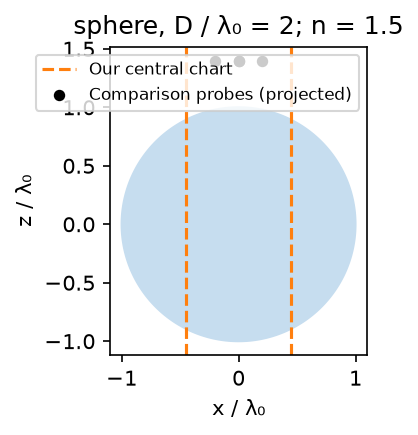

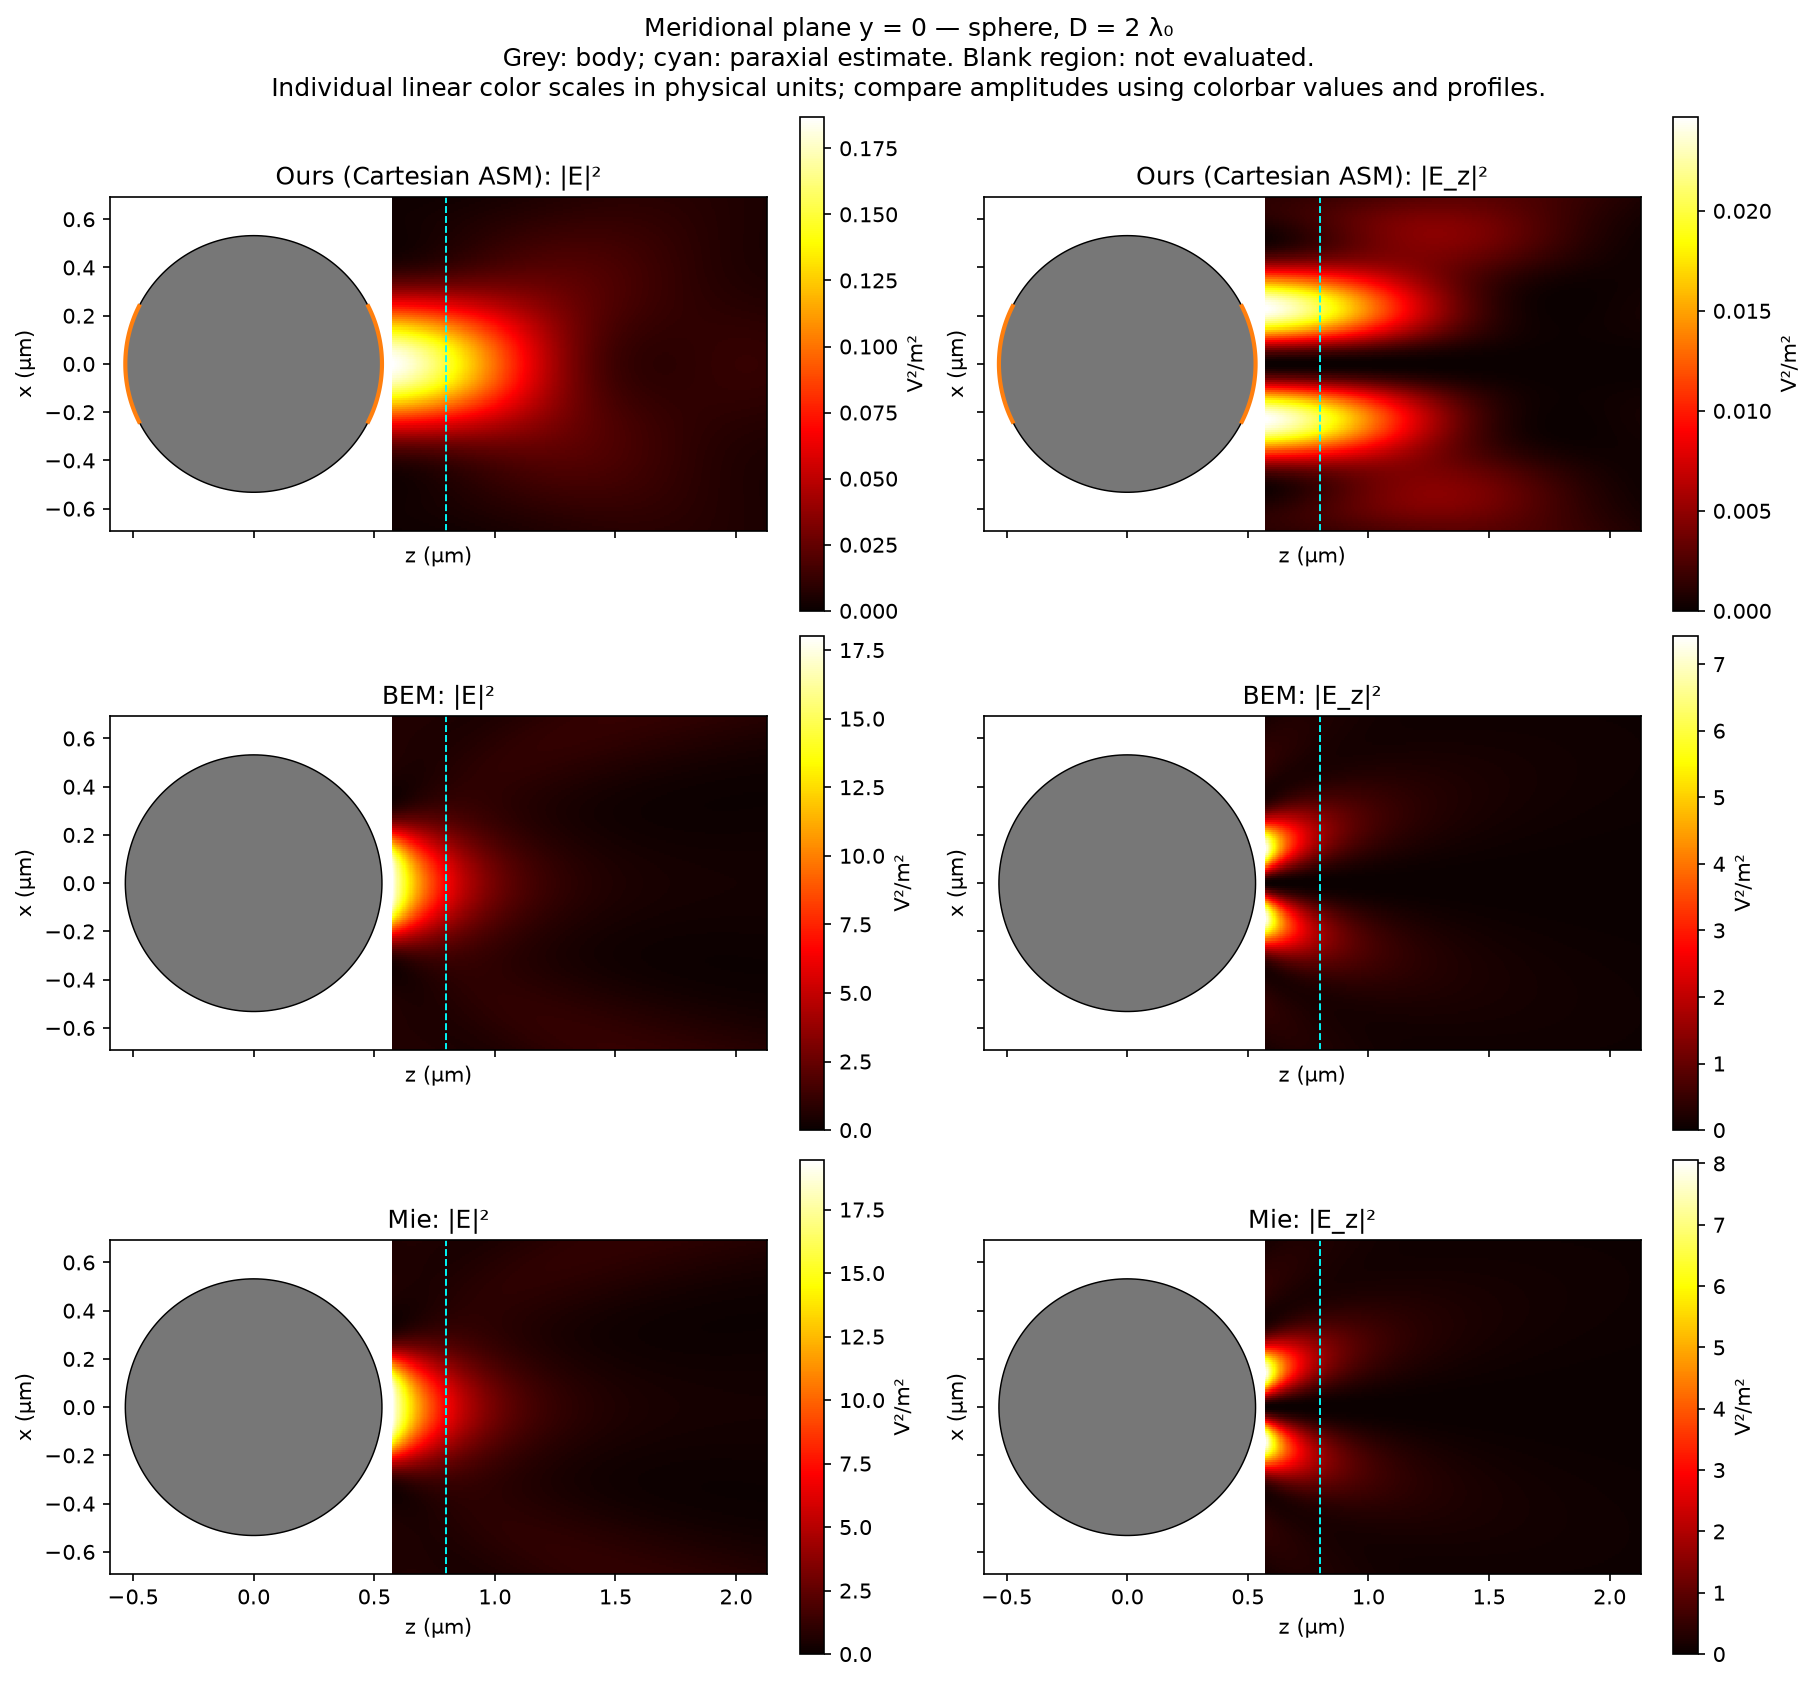

**Common detector plane:** z = 0.798 µm (paraxial estimate; no interior axial maximum in the observation window). Every method is evaluated at this identical plane; no independent peak alignment is applied. For wavelength-scale objects an axial maximum does not by itself establish a geometrical focus.

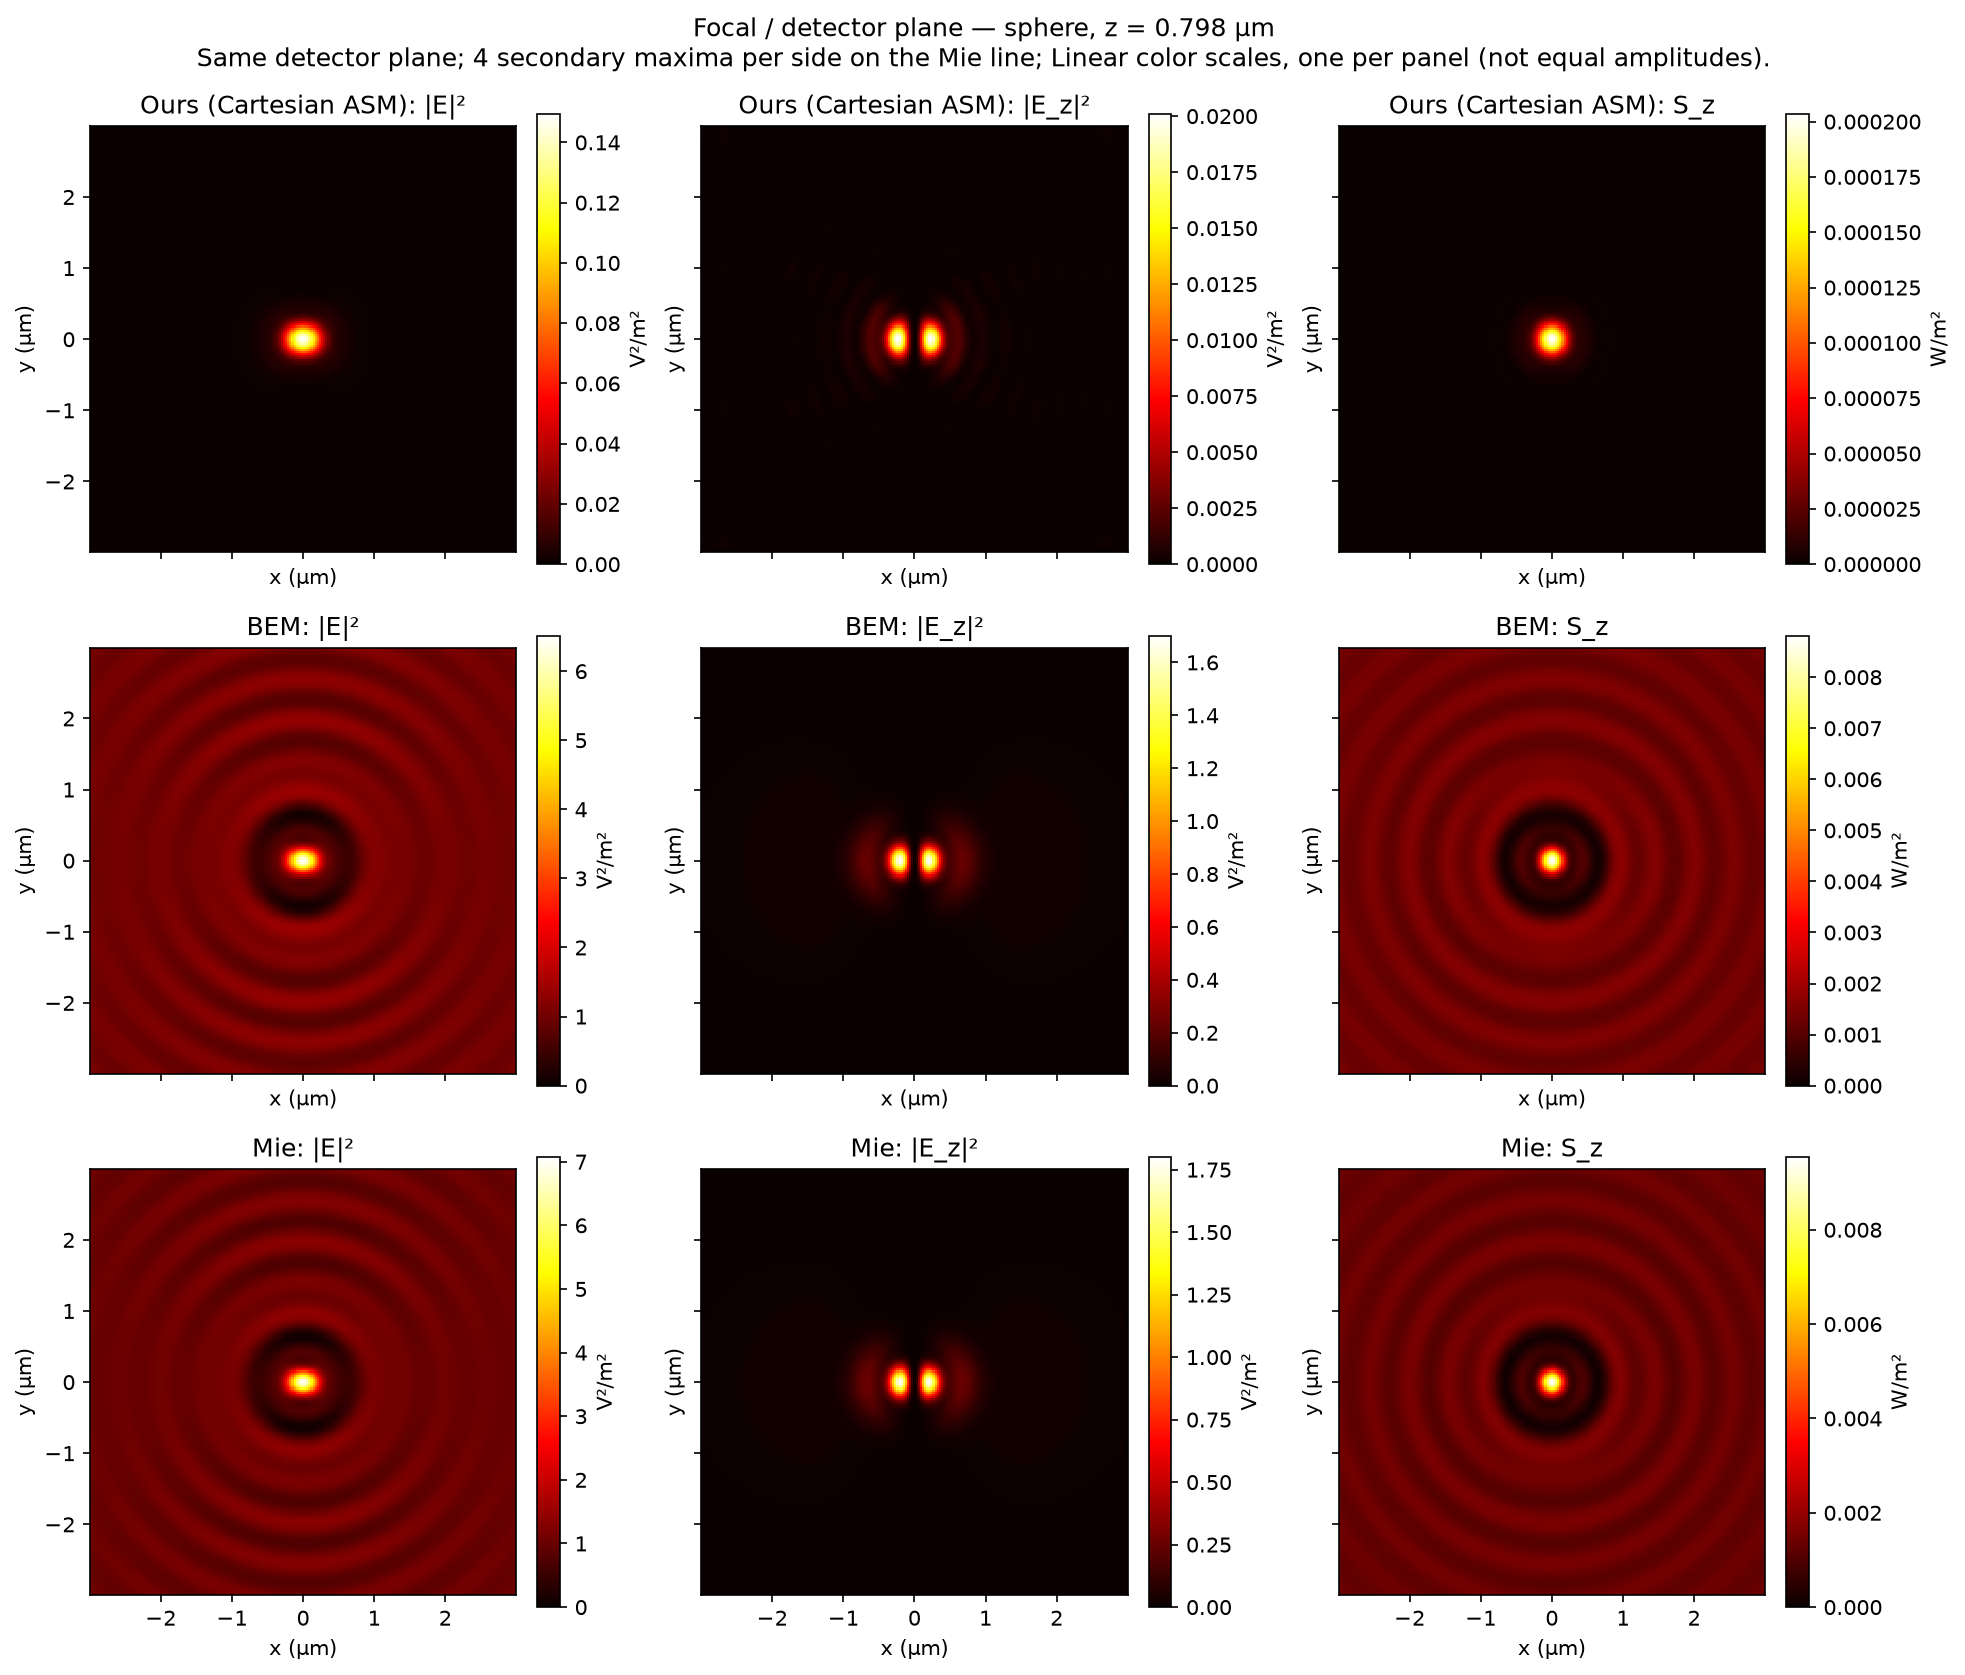

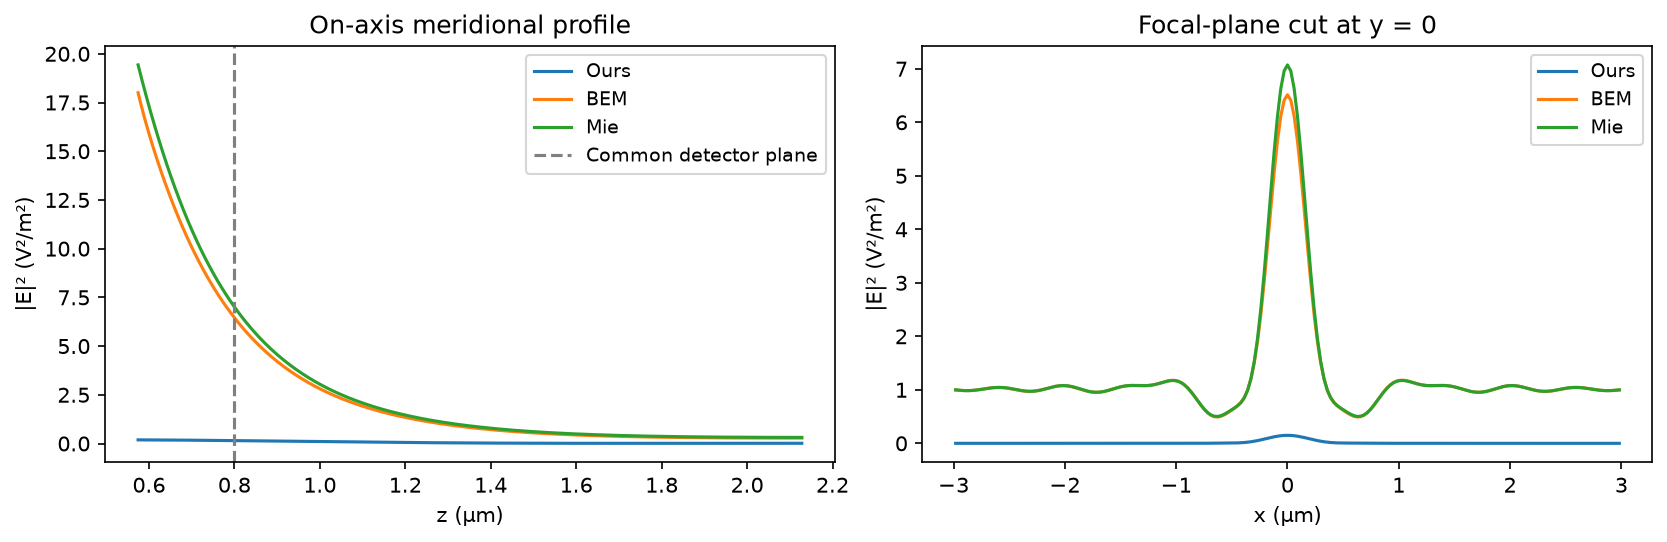

**FEM status:** the available coarse field is unresolved; inspect the mesh diagnostic below.

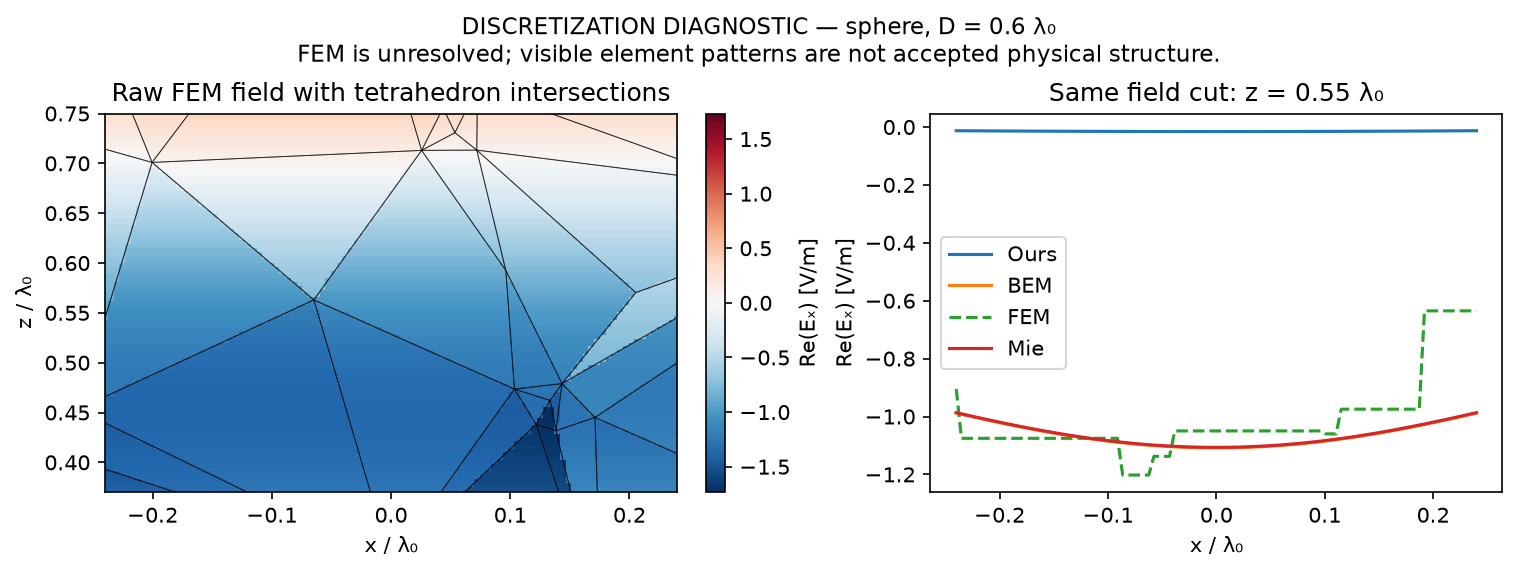

In [3]:
sphere_cases = []
for diameter in (0.6, 1.2, 2.0):
    print(f"Sphere D/λ₀={diameter}: assembling native references", flush=True)
    case = compare_case(
        "sphere",
        diameter,
        grids=(256, 384),
        window_apertures=24,
        bem_subdivisions=(1, 2, 3) if diameter == 0.6 else (1, 2),
        fem_sizes=(0.30, 0.22) if diameter < 2 else (0.35,),
        max_fem_unknowns=50000,
    )
    sphere_cases.append(case)
    cases.append(case)
report(sphere_cases)
geometry_view(sphere_cases[-1])
field_view(sphere_cases[-1])
fem_diagnostic(sphere_cases[0])

## Geometry 2 — Plano-convex lens (notebook 03 family)

The two surfaces and cylindrical rim form a closed body. Diameters are grouped in the following tables. Curvature radius is twice the diameter; axial thickness is 0.3 times the diameter. Our 4λ lens uses approximate forward rim coupling; BEM also includes sidewall reflection and returning waves. At 4λ, the default FEM volume budget is not attempted. The BEM gap is a comparison against the finest displayed BEM result, not an assertion of exactness.

plano-convex D/λ₀=1.0


plano-convex D/λ₀=2.0


plano-convex D/λ₀=4.0


### Field comparison and numerical refinement

D / λ₀,Method,Resolution¹,FFT width / clear radius,Relative E gap²,Refinement change,Interpretation
1,Ours,384,24,7.097e-02,2.454e-03,single pass: no rim scattering or internal returns
1,BEM,924,—,0.000e+00,2.730e-03,refinement required
1,FEM,0.22,—,1.691e-01,4.070e-01,refinement required
2,Ours,384,24,3.780e-01,8.451e-03,single pass: no rim scattering or internal returns
2,BEM,924,—,0.000e+00,1.398e-02,refinement required
2,FEM,0.35,—,1.094e+00,—,refinement required
4,Ours,384,24,5.625e-01,3.275e-02,forward coupled rim; no sidewall reflection or internal returns
4,BEM,924,—,0.000e+00,3.251e-01,refinement required
4,FEM,—,—,—,—,not run: volume mesh budget


...

D / λ₀,Method,Boundary tested,Tangential E,Tangential H,Normal D,Normal B,Flux residual,Flux definition
1,Ours,forward trace + local reflection,4.148e-01,6.980e-01,6.110e-01,3.452e-01,1.513e-01,transmission reconstruction
1,BEM,full boundary; mesh face centres,1.481e-01,1.795e-01,2.893e-01,1.883e-01,6.612e-05,net closed-surface total power
1,FEM,full boundary; mesh face centres,5.784e-16,1.267e+00,9.160e-01,1.093e-15,4.989e-03,net closed-surface total power
2,Ours,forward trace + local reflection,3.261e-01,4.836e-01,5.159e-01,2.995e-01,7.875e-02,transmission reconstruction
2,BEM,full boundary; mesh face centres,2.465e-01,2.792e-01,4.275e-01,2.552e-01,2.900e-04,net closed-surface total power
2,FEM,full boundary; mesh face centres,8.397e-16,2.249e+00,2.395e+00,8.124e-16,2.084e-02,net closed-surface total power
4,Ours,forward trace + local reflection,8.886e-01,9.023e-01,6.579e-01,5.224e-01,1.617e-01,transmission reconstruction
4,BEM,full boundary; mesh face centres,6.544e-01,9.354e-01,9.691e-01,1.372e+00,3.494e-03,net closed-surface total power
4,FEM,—,—,—,—,—,—,—


### Equations and execution time

D / λ₀,Method,Strong PDE residual³,Weak solve residual,Mesh [s],Build + solve [s],Four probes [s]
1,Ours,1.361e-06,—,0,1.267e+00,1.652e-02
1,BEM,1.694e-06,1.294e-14,2.124e-02,6.843e-03,2.605e-03
1,FEM,—,8.561e-14,2.115e-01,2.477e-03,4.763e-04
2,Ours,1.617e-06,—,0,2.097e+00,2.354e-02
2,BEM,1.578e-06,1.303e-14,2.562e-02,8.753e-03,4.092e-03
2,FEM,—,5.057e-14,1.390e-01,2.385e-03,5.788e-04
4,Ours,1.372e-06,—,0,2.478e+00,6.695e-02
4,BEM,5.342e-05,1.317e-14,3.774e-02,1.013e-02,3.883e-03
4,FEM,—,—,—,—,—


### All refinement runs (same geometry; parameters grouped)

D / λ₀,Method,Resolution¹,FFT width / clear radius,Refinement change,Build + solve [s],Interpretation
1,Ours,256,24,—,5.021e-01,single pass: no rim scattering or internal returns
1,Ours,384,24,2.454e-03,1.267e+00,single pass: no rim scattering or internal returns
1,BEM,414,—,—,9.765e-03,refinement required
1,BEM,924,—,2.730e-03,6.843e-03,refinement required
1,FEM,0.3,—,—,2.205e-03,refinement required
1,FEM,0.22,—,4.070e-01,2.477e-03,refinement required
2,Ours,256,24,—,7.471e-01,single pass: no rim scattering or internal returns
2,Ours,384,24,8.451e-03,2.097e+00,single pass: no rim scattering or internal returns
2,BEM,414,—,—,7.126e-03,refinement required
2,BEM,924,—,1.398e-02,8.753e-03,refinement required


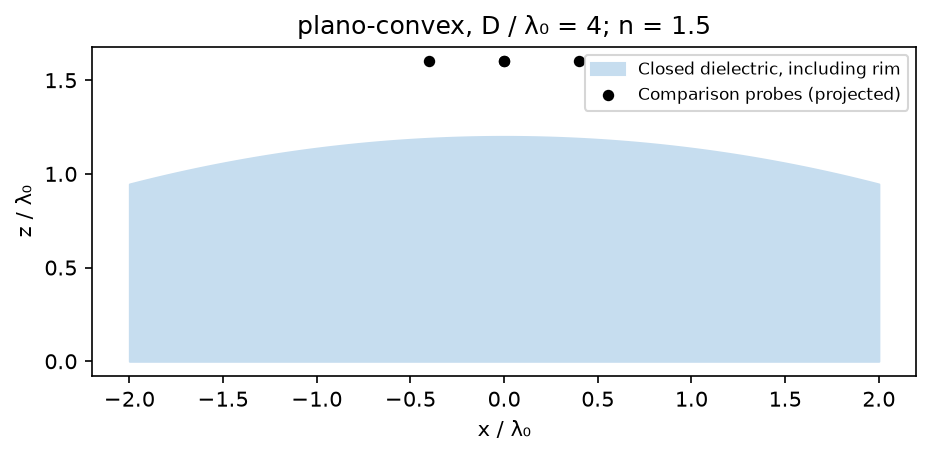

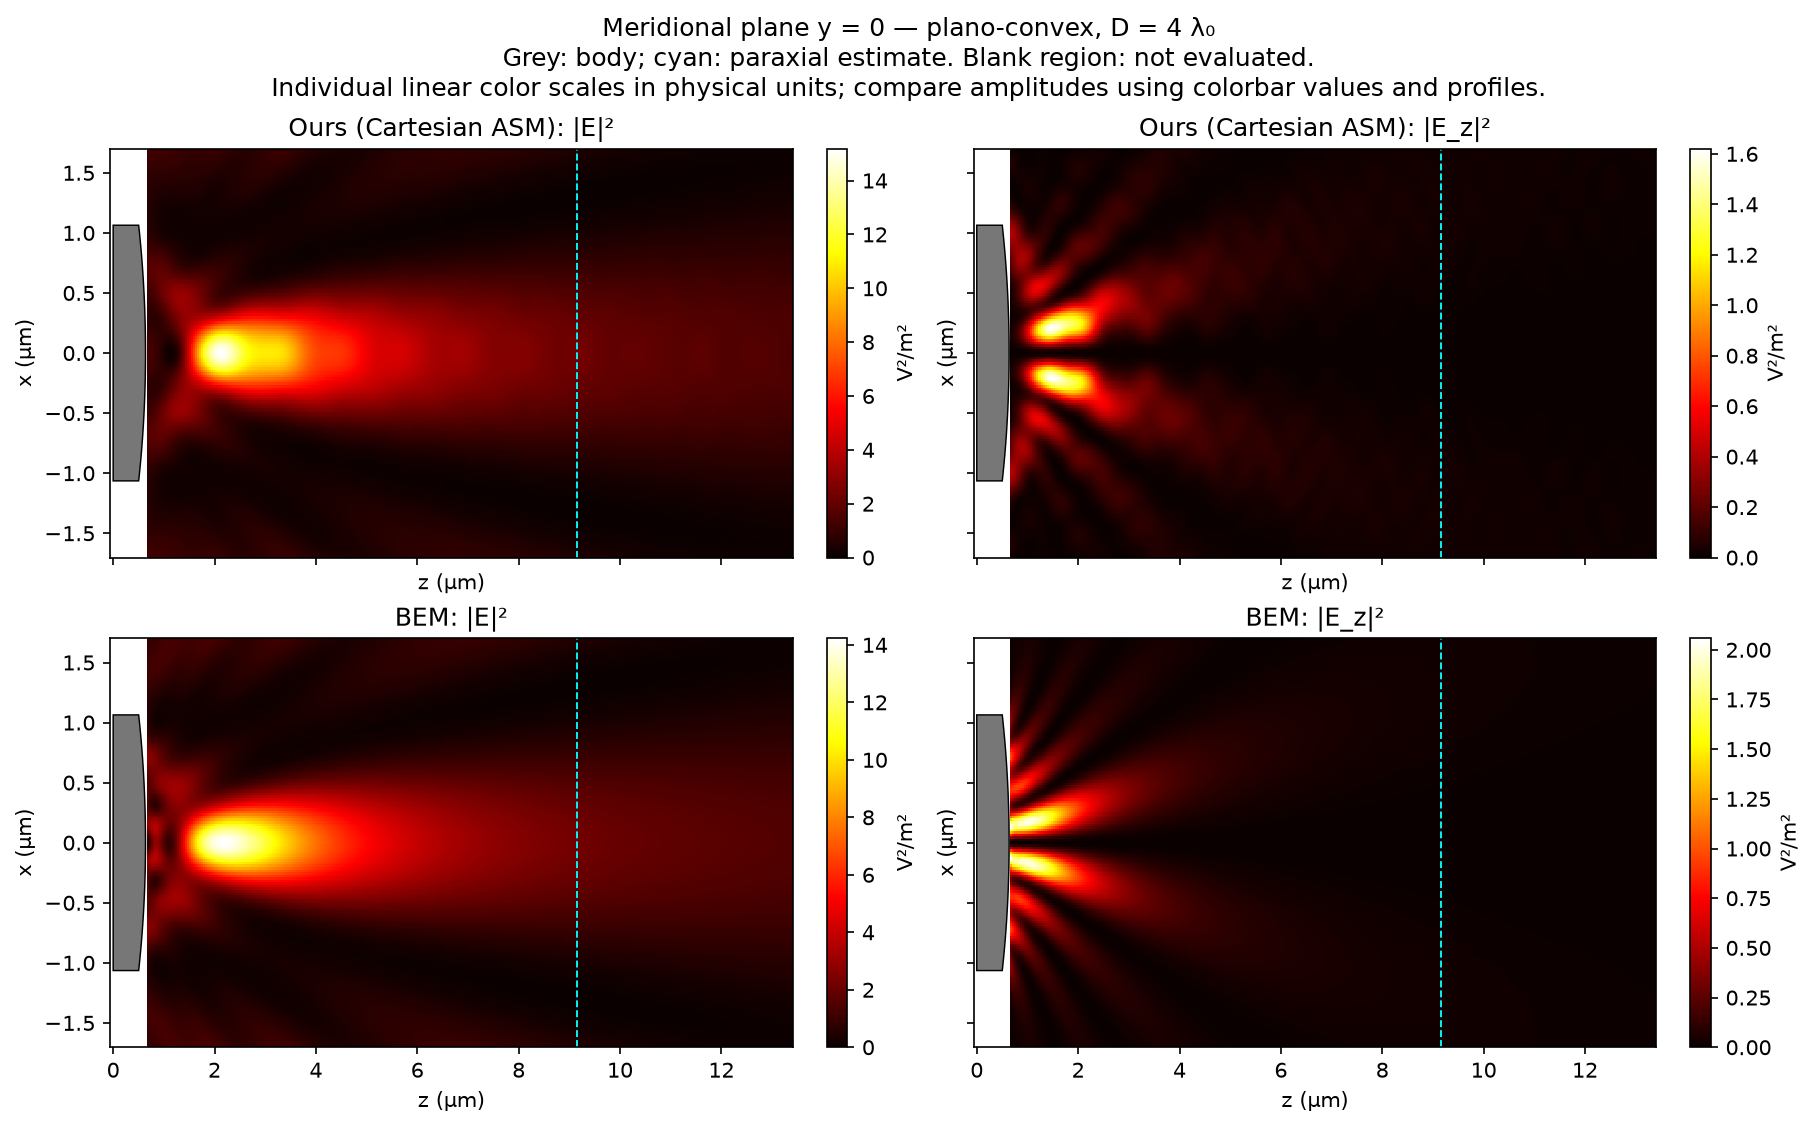

**Common detector plane:** z = 2.192 µm (sampled on-axis maximum of BEM). Every method is evaluated at this identical plane; no independent peak alignment is applied. For wavelength-scale objects an axial maximum does not by itself establish a geometrical focus.

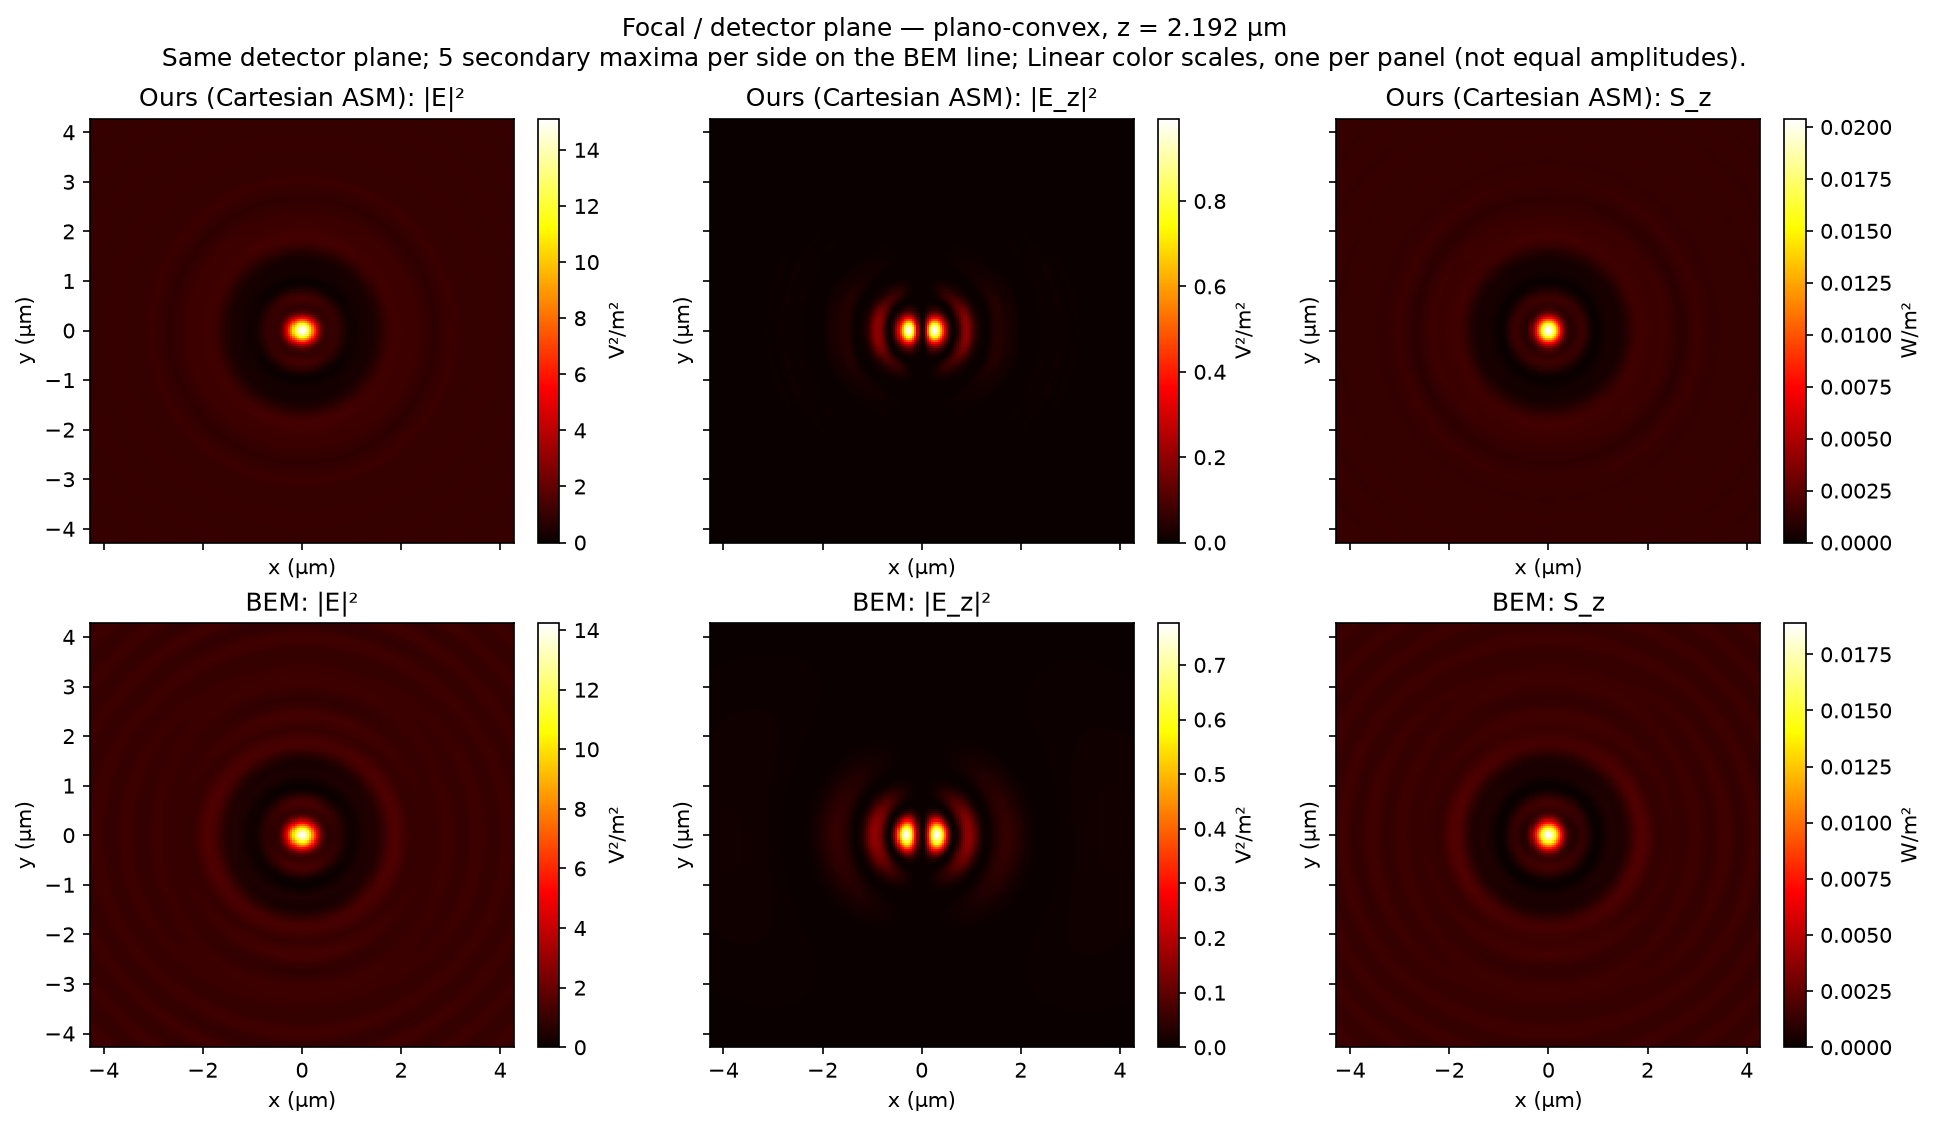

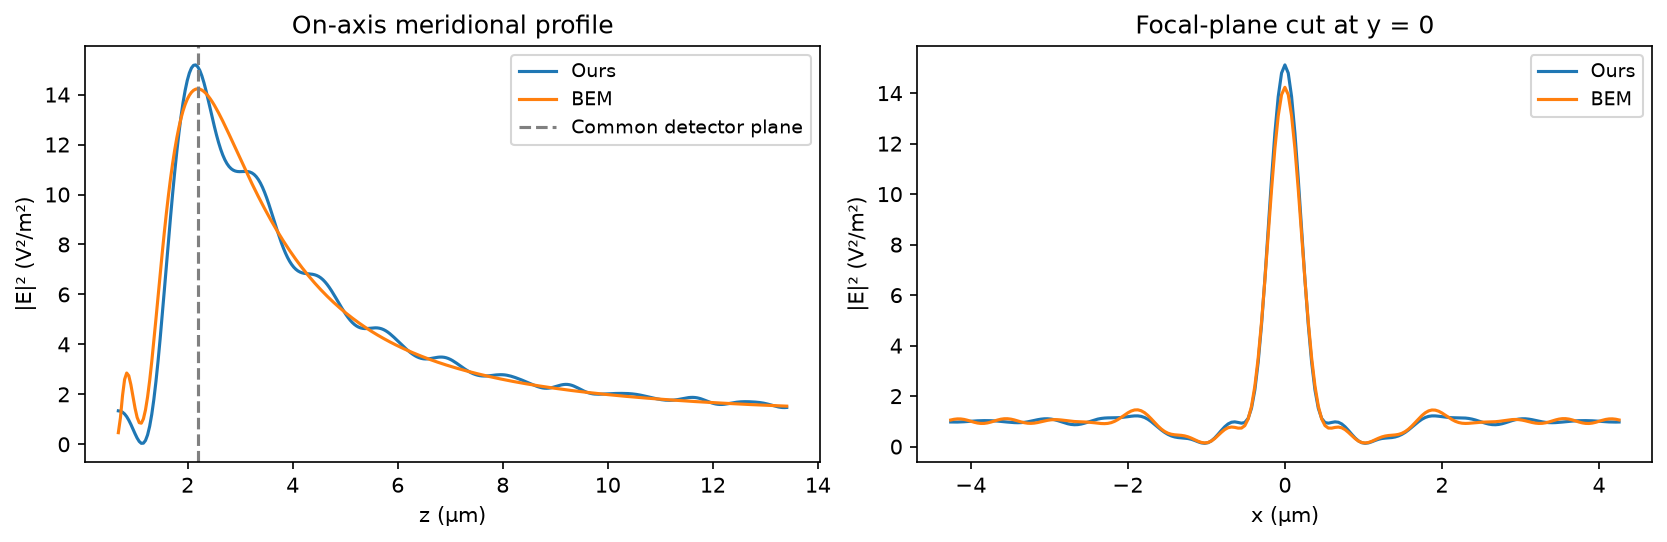

**FEM status:** no volume solution was run at this size; no FEM focal map is available.

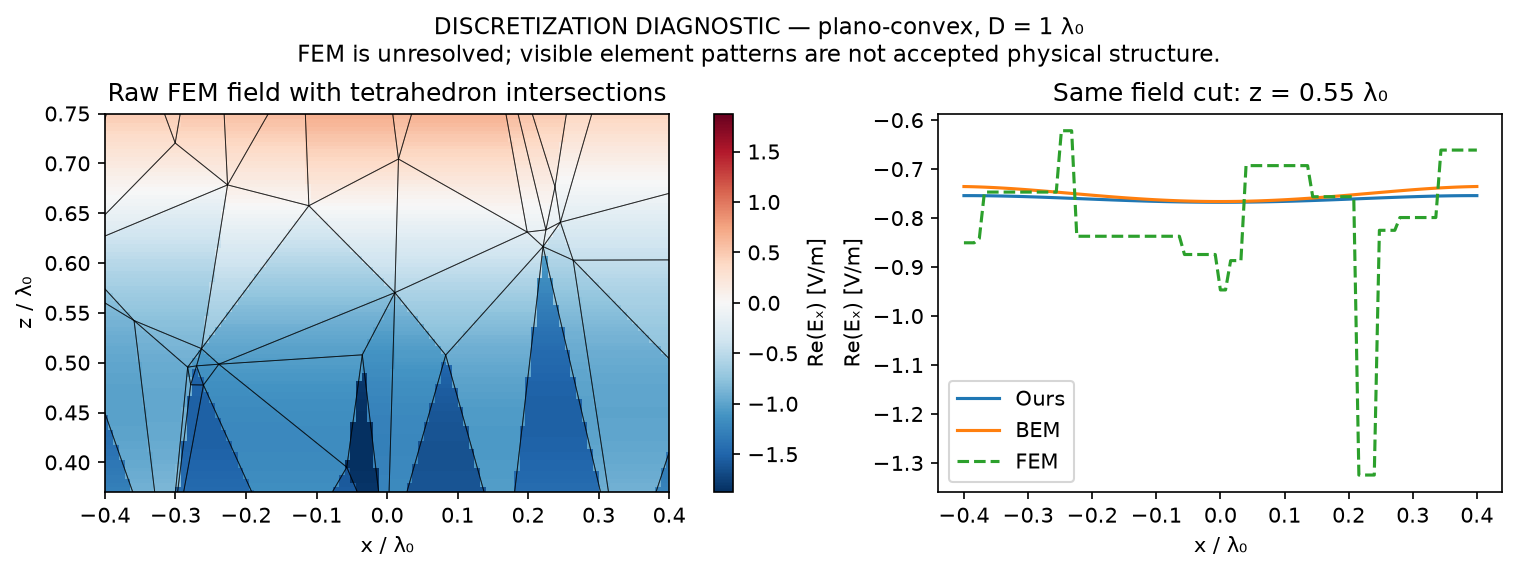

In [4]:
plano_cases = []
for diameter in (1.0, 2.0, 4.0):
    print(f"plano-convex D/λ₀={diameter}", flush=True)
    case = compare_case(
        "plano-convex",
        diameter,
        grids=(256, 384),
        window_apertures=24,
        bem_divisors=(8, 12),
        fem_sizes=(0.30, 0.22) if diameter == 1 else (0.35,),
        run_fem=diameter <= 2,
        max_fem_unknowns=50000,
    )
    plano_cases.append(case)
    cases.append(case)
report(plano_cases)
geometry_view(plano_cases[-1])
field_view(plano_cases[-1])
fem_diagnostic(plano_cases[0])

## Geometry 3 — Biconvex lens

The two surfaces and cylindrical rim form a closed body. Diameters are grouped in the following tables. Curvature radius is twice the diameter; axial thickness is 0.3 times the diameter. Our 4λ lens uses approximate forward rim coupling; BEM also includes sidewall reflection and returning waves. At 4λ, the default FEM volume budget is not attempted. The BEM gap is a comparison against the finest displayed BEM result, not an assertion of exactness.

biconvex D/λ₀=1.0


biconvex D/λ₀=2.0


biconvex D/λ₀=4.0


### Field comparison and numerical refinement

D / λ₀,Method,Resolution¹,FFT width / clear radius,Relative E gap²,Refinement change,Interpretation
1,Ours,384,24,7.941e-02,1.868e-03,single pass: no rim scattering or internal returns
1,BEM,900,—,0.000e+00,2.944e-03,refinement required
1,FEM,0.22,—,2.259e-01,3.380e-01,refinement required
2,Ours,384,24,2.665e-01,6.654e-03,single pass: no rim scattering or internal returns
2,BEM,900,—,0.000e+00,5.838e-03,refinement required
2,FEM,0.35,—,9.735e-01,—,refinement required
4,Ours,384,24,4.147e-01,2.057e-02,forward coupled rim; no sidewall reflection or internal returns
4,BEM,900,—,0.000e+00,7.466e-02,refinement required
4,FEM,—,—,—,—,not run: volume mesh budget


...

D / λ₀,Method,Boundary tested,Tangential E,Tangential H,Normal D,Normal B,Flux residual,Flux definition
1,Ours,forward trace + local reflection,4.083e-01,6.926e-01,6.102e-01,3.448e-01,1.516e-01,transmission reconstruction
1,BEM,full boundary; mesh face centres,1.558e-01,1.790e-01,2.907e-01,1.926e-01,3.454e-05,net closed-surface total power
1,FEM,full boundary; mesh face centres,5.272e-16,1.105e+00,9.620e-01,9.661e-16,5.257e-02,net closed-surface total power
2,Ours,forward trace + local reflection,3.828e-01,4.828e-01,5.241e-01,3.007e-01,7.797e-02,transmission reconstruction
2,BEM,full boundary; mesh face centres,2.553e-01,2.708e-01,3.990e-01,2.279e-01,1.798e-04,net closed-surface total power
2,FEM,full boundary; mesh face centres,9.601e-16,2.099e+00,2.242e+00,9.387e-16,2.071e-02,net closed-surface total power
4,Ours,forward trace + local reflection,6.302e-01,6.308e-01,5.717e-01,4.406e-01,1.181e-01,transmission reconstruction
4,BEM,full boundary; mesh face centres,4.607e-01,7.385e-01,8.702e-01,9.083e-01,2.627e-03,net closed-surface total power
4,FEM,—,—,—,—,—,—,—


### Equations and execution time

D / λ₀,Method,Strong PDE residual³,Weak solve residual,Mesh [s],Build + solve [s],Four probes [s]
1,Ours,1.337e-06,—,0,1.940e+00,1.593e-02
1,BEM,1.626e-06,1.327e-14,2.282e-02,6.537e-03,2.537e-03
1,FEM,—,5.056e-14,1.949e-01,2.031e-03,4.034e-04
2,Ours,1.593e-06,—,0,2.407e+00,2.614e-02
2,BEM,1.597e-06,1.224e-14,3.236e-02,1.007e-02,3.641e-03
2,FEM,—,3.342e-14,1.601e-01,2.540e-03,5.889e-04
4,Ours,1.582e-06,—,0,3.516e+00,5.299e-02
4,BEM,3.058e-05,8.558e-15,3.494e-02,8.781e-03,3.893e-03
4,FEM,—,—,—,—,—


### All refinement runs (same geometry; parameters grouped)

D / λ₀,Method,Resolution¹,FFT width / clear radius,Refinement change,Build + solve [s],Interpretation
1,Ours,256,24,—,8.389e-01,single pass: no rim scattering or internal returns
1,Ours,384,24,1.868e-03,1.940e+00,single pass: no rim scattering or internal returns
1,BEM,426,—,—,4.172e-03,refinement required
1,BEM,900,—,2.944e-03,6.537e-03,refinement required
1,FEM,0.3,—,—,1.891e-03,refinement required
1,FEM,0.22,—,3.380e-01,2.031e-03,refinement required
2,Ours,256,24,—,9.184e-01,single pass: no rim scattering or internal returns
2,Ours,384,24,6.654e-03,2.407e+00,single pass: no rim scattering or internal returns
2,BEM,426,—,—,5.541e-03,refinement required
2,BEM,900,—,5.838e-03,1.007e-02,refinement required


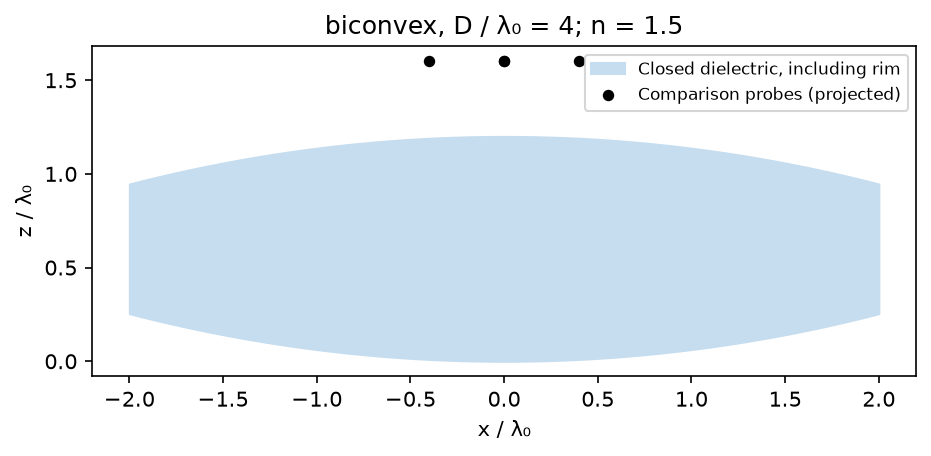

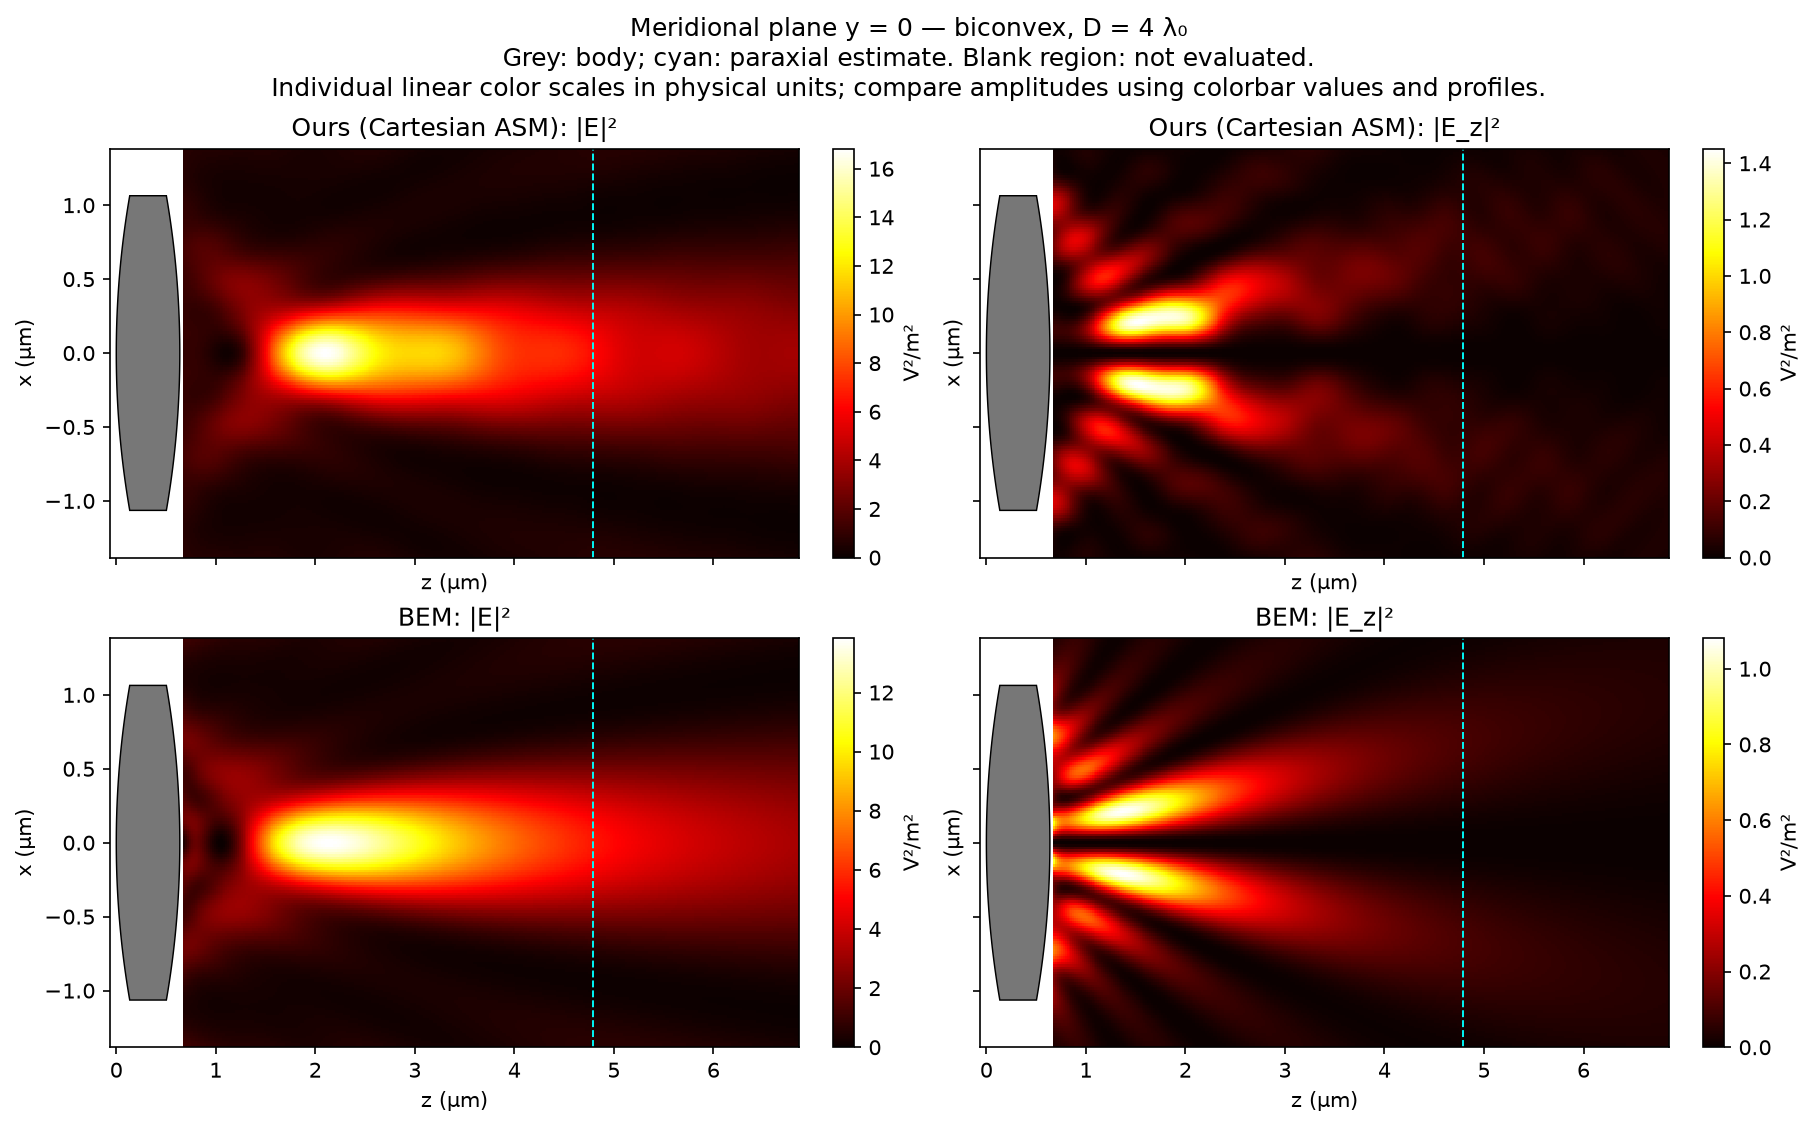

**Common detector plane:** z = 2.129 µm (sampled on-axis maximum of BEM). Every method is evaluated at this identical plane; no independent peak alignment is applied. For wavelength-scale objects an axial maximum does not by itself establish a geometrical focus.

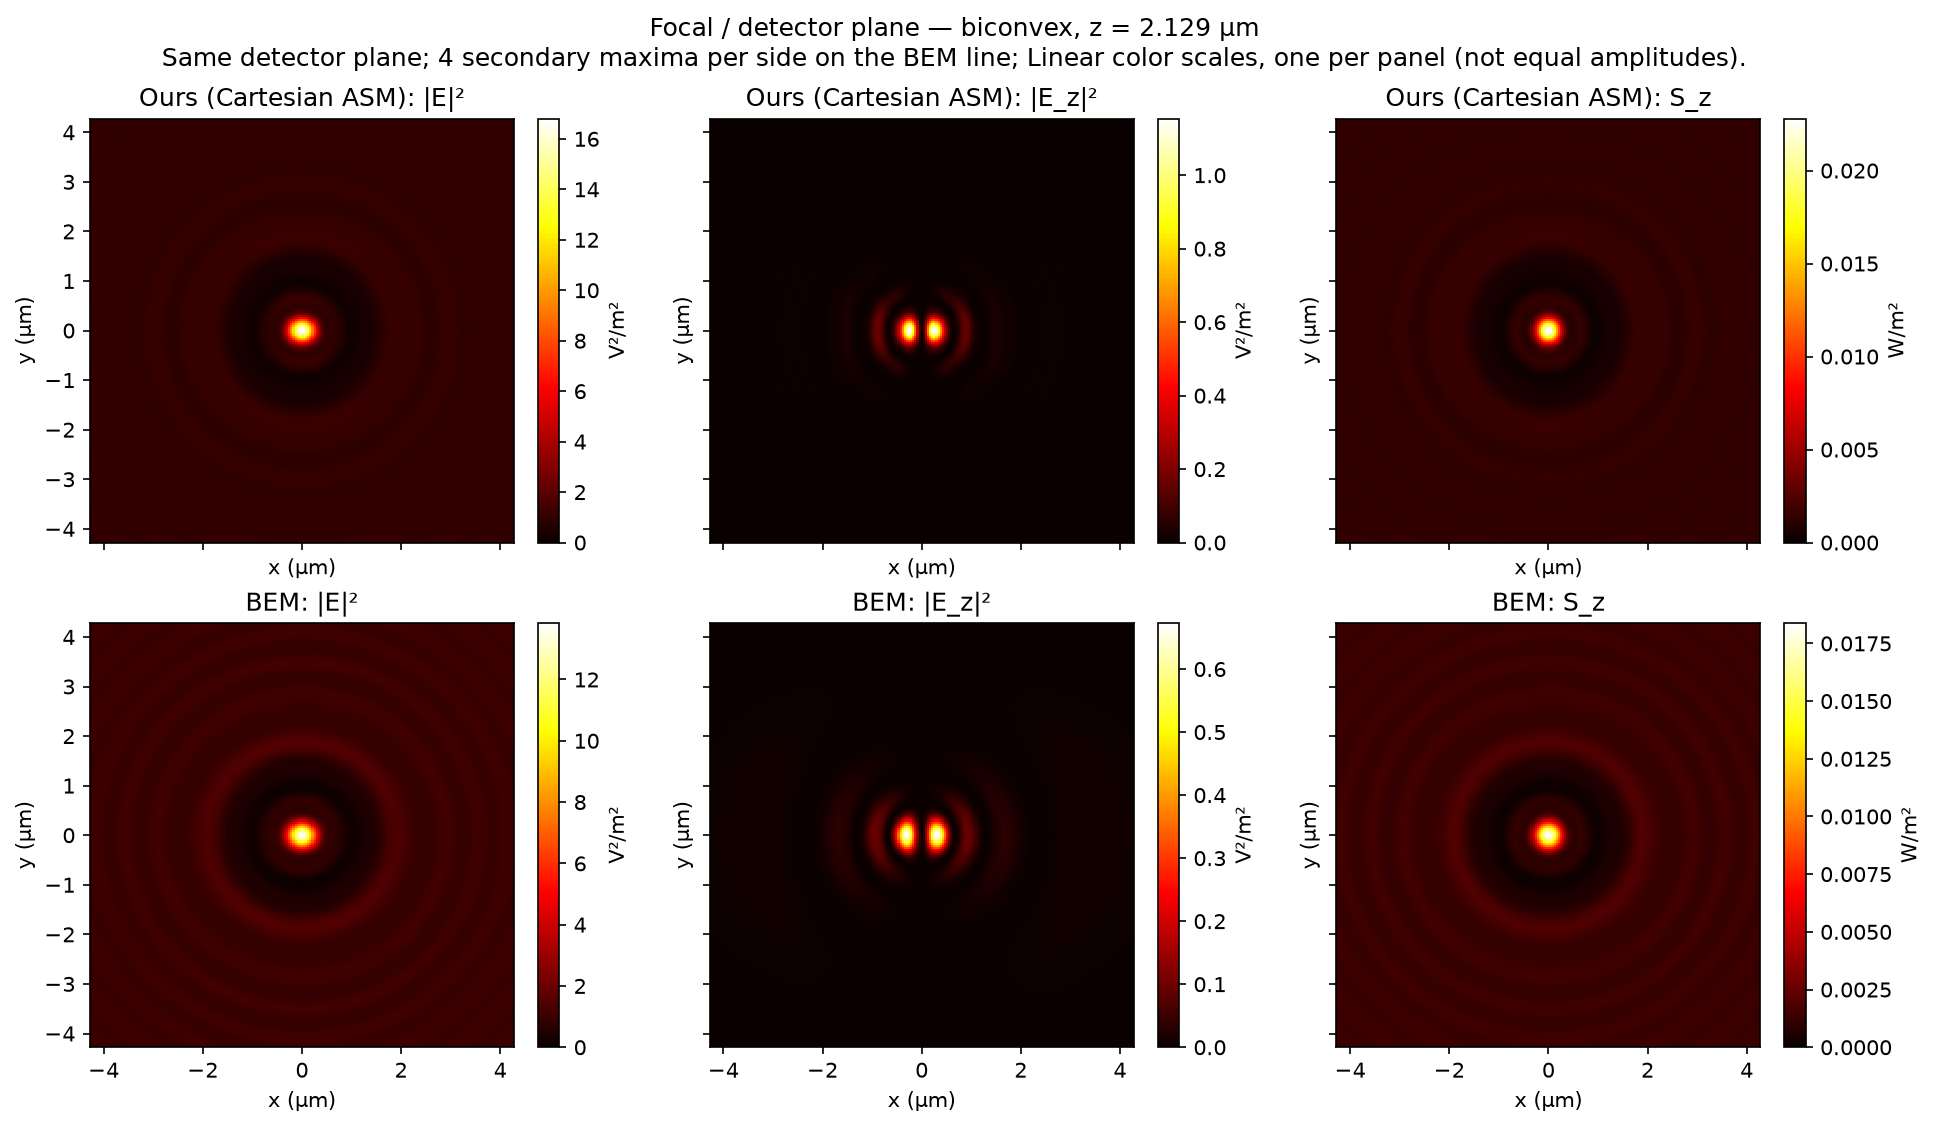

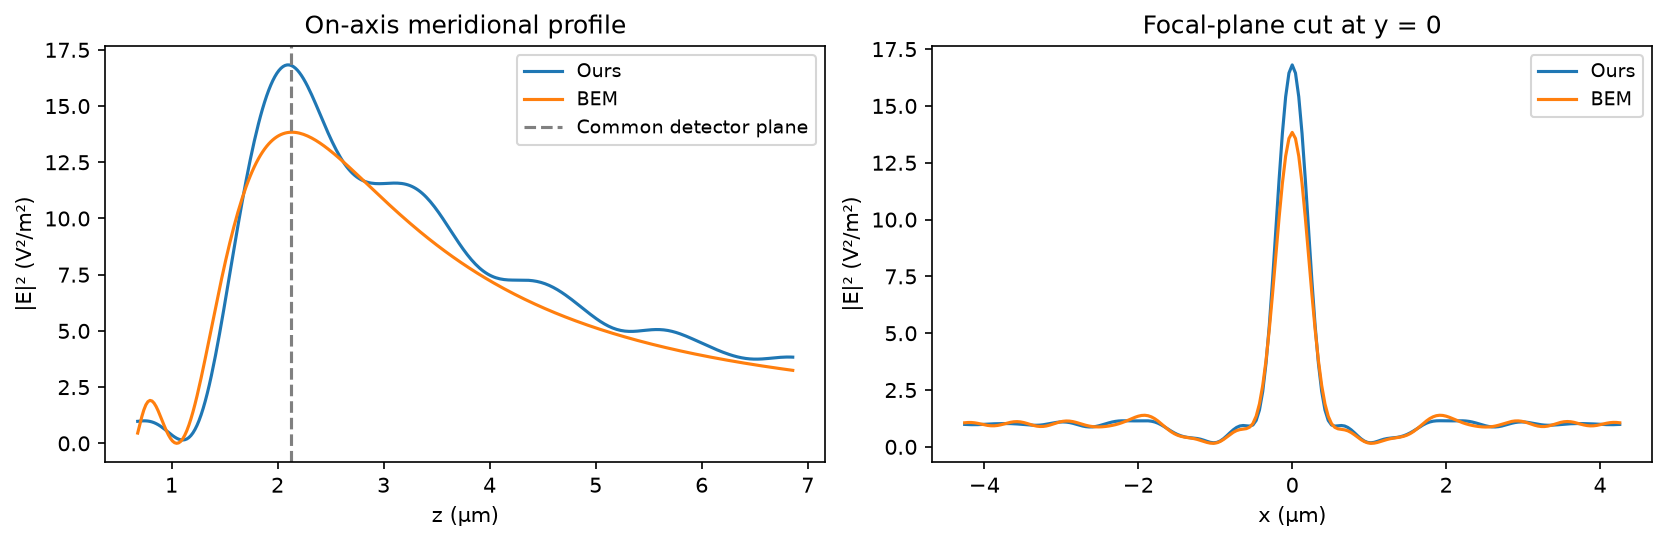

**FEM status:** no volume solution was run at this size; no FEM focal map is available.

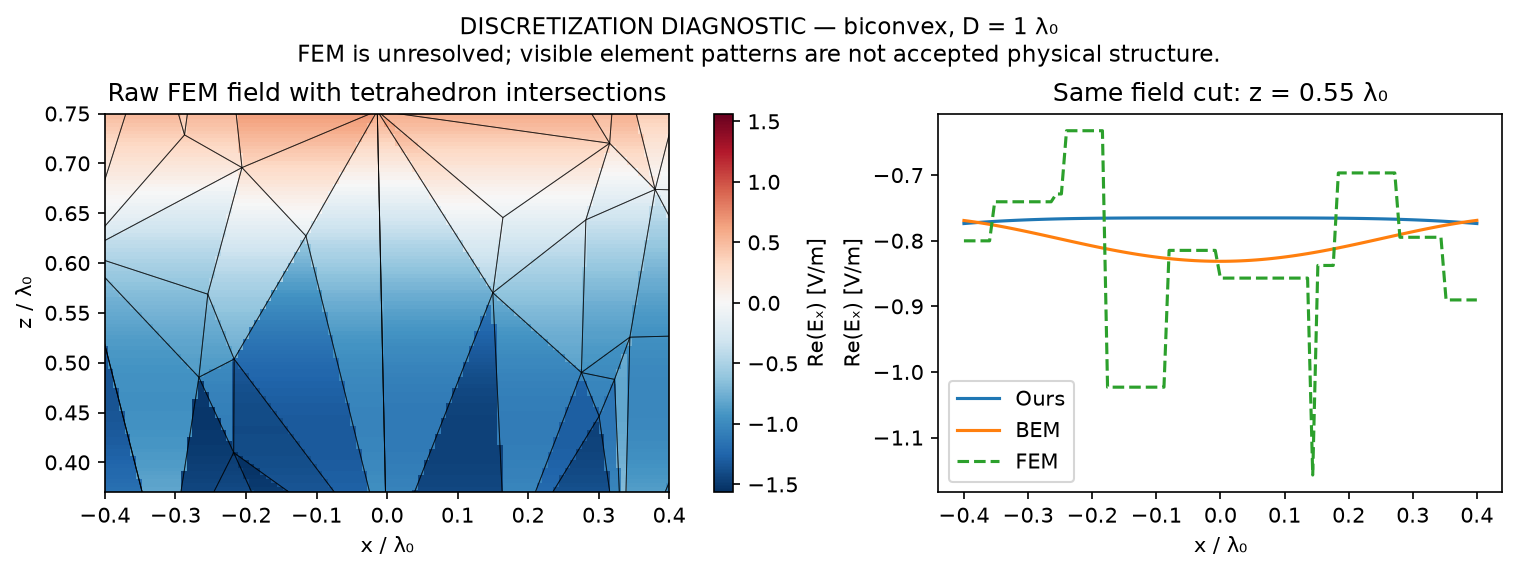

In [5]:
biconvex_cases = []
for diameter in (1.0, 2.0, 4.0):
    print(f"biconvex D/λ₀={diameter}", flush=True)
    case = compare_case(
        "biconvex",
        diameter,
        grids=(256, 384),
        window_apertures=24,
        bem_divisors=(8, 12),
        fem_sizes=(0.30, 0.22) if diameter == 1 else (0.35,),
        run_fem=diameter <= 2,
        max_fem_unknowns=50000,
    )
    biconvex_cases.append(case)
    cases.append(case)
report(biconvex_cases)
geometry_view(biconvex_cases[-1])
field_view(biconvex_cases[-1])
fem_diagnostic(biconvex_cases[0])

## Geometry 4 — 6λ₀ lenses: when does rim coupling help?

Our method follows one forward wave through each lens. The original path carries light inside the glass and outside in air independently until the exit. The new conditional path exchanges the two across the cylindrical rim in thin axial steps. It applies here when the element Fresnel number a²/(λ₀T) is at most 8; thin lenses retain the original path. This step does not enforce full vector sidewall boundary conditions or include returns.

The 6λ₀ lenses below (n = 1.5, unit x-polarized plane wave) use cached BEM fields at element sizes λ₀/3 and λ₀/4 (`lens_references.py`). First the reference itself: BEM against exact Mie for a 6λ₀ sphere. Then both forward paths are compared with BEM λ₀/4 over the same axis points.


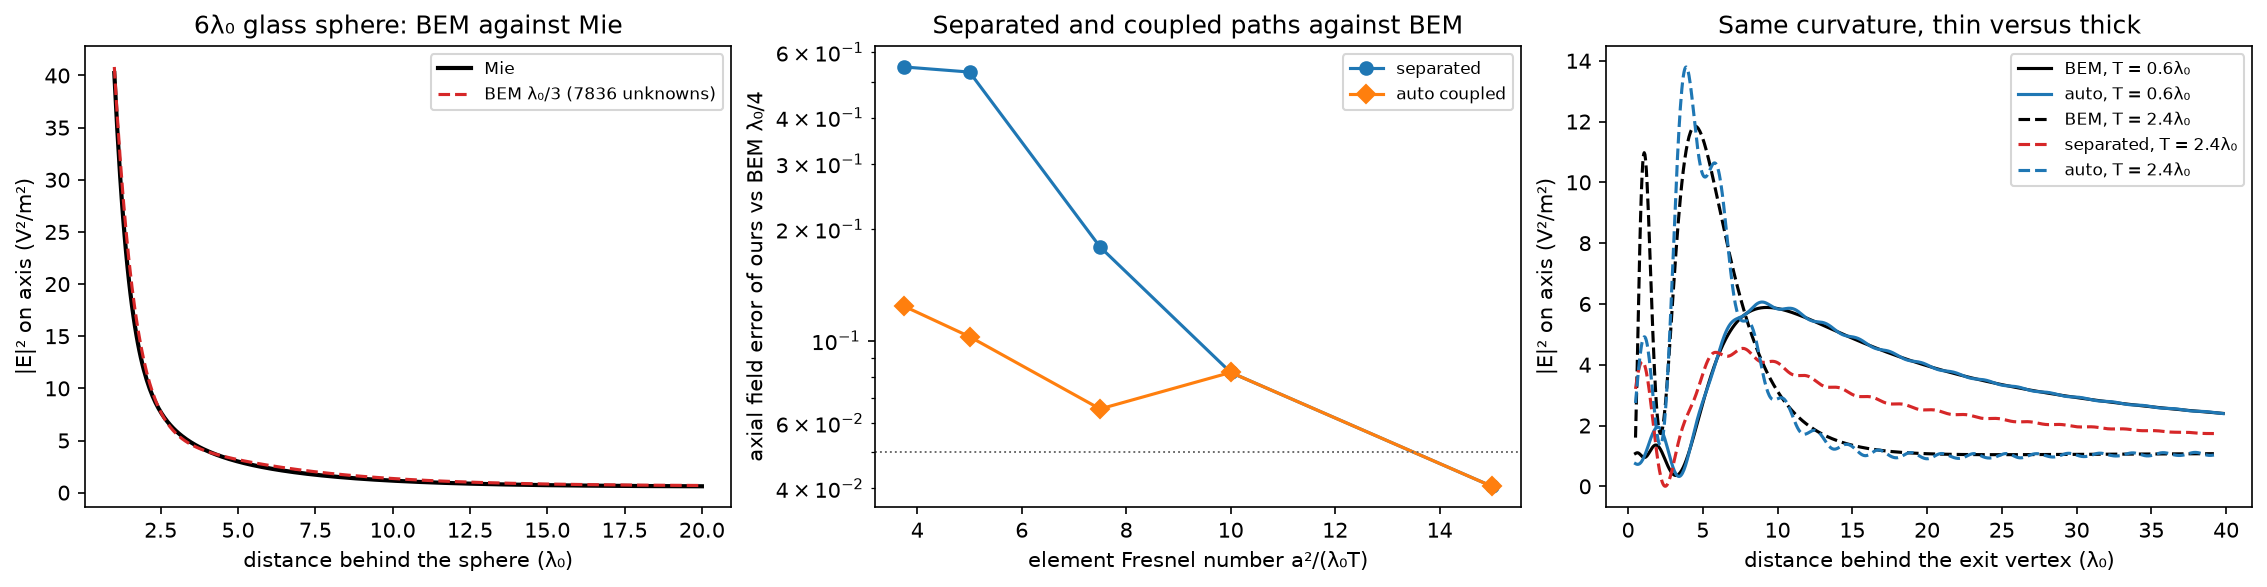

BEM λ₀/3 against Mie, complex field on the axis: **6.9%**.

Lens group,Lens,Centre thickness T (λ₀),Element Fresnel number a²/(λ₀T),Separated axial E gap vs BEM λ₀/4,Auto coupled axial E gap vs BEM λ₀/4,"BEM change, λ₀/3 → λ₀/4"
"biconvex R = ±20λ₀, thickness sweep","biconvex R20, T 0.6",0.6,15.0,0.041,0.041,0.006
"biconvex R = ±20λ₀, thickness sweep","biconvex R20, T 0.9",0.9,10.0,0.082,0.082,0.005
"biconvex R = ±20λ₀, thickness sweep","biconvex R20, T 1.2",1.2,7.5,0.179,0.066,0.015
"biconvex R = ±20λ₀, thickness sweep","biconvex R20, T 1.8",1.8,5.0,0.531,0.103,0.035
"biconvex R = ±20λ₀, thickness sweep","biconvex R20, T 2.4",2.4,3.8,0.548,0.124,0.054
thin lenses,thin plano-convex,0.7,12.9,0.037,0.037,0.010
thin lenses,thin convex-plano,0.7,12.9,0.035,0.035,0.007
thin lenses,thin biconvex,0.7,12.9,0.037,0.037,0.007
thin lenses,thin asymmetric biconvex,0.7,12.9,0.034,0.034,0.009


In [6]:
import lens_references as lenses

sphere, sphere_info = lenses.sphere_control(verbose=False)
behind = sphere["z"] / WAVELENGTH - lenses.DIAMETER / 2
validity_rows, profiles = [], {}
for group, names in (
    ("biconvex R = ±20λ₀, thickness sweep", lenses.SWEEP),
    ("thin lenses", lenses.MAIN),
):
    for name in names:
        result = lenses.validity(name)
        profiles[name] = result
        validity_rows.append(
            dict(
                group=group,
                lens=name,
                thickness=f"{lenses.LENSES[name][2]:g}",
                fresnel=f"{lenses.element_fresnel(name):.1f}",
                uncoupled=f"{result['error_uncoupled']:.3f}",
                error=f"{result['error']:.3f}",
                bem=f"{result['bem_change']:.3f}",
            )
        )

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), layout="constrained")
axes[0].plot(
    behind, np.sum(abs(sphere["mie"]) ** 2, -1), color="black", lw=2, label="Mie"
)
axes[0].plot(
    behind,
    np.sum(abs(sphere["bem"]) ** 2, -1),
    color="tab:red",
    ls="--",
    label=f"BEM λ₀/3 ({sphere_info['unknowns']} unknowns)",
)
axes[0].set(
    xlabel="distance behind the sphere (λ₀)",
    ylabel="|E|² on axis (V²/m²)",
    title="6λ₀ glass sphere: BEM against Mie",
)
axes[0].legend(fontsize=8)
for label, key, marker in (
    ("separated", "error_uncoupled", "o"),
    ("auto coupled", "error", "D"),
):
    axes[1].plot(
        [lenses.element_fresnel(n) for n in lenses.SWEEP],
        [profiles[n][key] for n in lenses.SWEEP],
        marker + "-",
        ms=6,
        label=label,
    )
axes[1].axhline(0.05, color="0.4", ls=":", lw=0.9)
axes[1].set(
    xlabel="element Fresnel number a²/(λ₀T)",
    ylabel="axial field error of ours vs BEM λ₀/4",
    yscale="log",
    title="Separated and coupled paths against BEM",
)
axes[1].legend(fontsize=8)
for name, style in ((lenses.SWEEP[0], "-"), (lenses.SWEEP[-1], "--")):
    data = profiles[name]
    z = data["z"] / WAVELENGTH - lenses.LENSES[name][2]
    t = lenses.LENSES[name][2]
    axes[2].plot(
        z,
        np.sum(abs(data["bem"]) ** 2, -1),
        color="black",
        ls=style,
        label=f"BEM, T = {t:g}λ₀",
    )
    if name == lenses.SWEEP[-1]:
        axes[2].plot(
            z,
            np.sum(abs(data["uncoupled"]) ** 2, -1),
            color="tab:red",
            ls=style,
            label=f"separated, T = {t:g}λ₀",
        )
    axes[2].plot(
        z,
        np.sum(abs(data["ours"]) ** 2, -1),
        color="tab:blue",
        ls=style,
        label=f"auto, T = {t:g}λ₀",
    )
axes[2].set(
    xlabel="distance behind the exit vertex (λ₀)",
    ylabel="|E|² on axis (V²/m²)",
    title="Same curvature, thin versus thick",
)
axes[2].legend(fontsize=8)
plt.show()
mie_error = np.linalg.norm(sphere["bem"] - sphere["mie"]) / np.linalg.norm(
    sphere["mie"]
)
display(
    Markdown(f"BEM λ₀/3 against Mie, complex field on the axis: **{mie_error:.1%}**.")
)
show(
    validity_rows,
    [
        ("group", "Lens group"),
        ("lens", "Lens"),
        ("thickness", "Centre thickness T (λ₀)"),
        ("fresnel", "Element Fresnel number a²/(λ₀T)"),
        ("uncoupled", "Separated axial E gap vs BEM λ₀/4"),
        ("error", "Auto coupled axial E gap vs BEM λ₀/4"),
        ("bem", "BEM change, λ₀/3 → λ₀/4"),
    ],
)

The thick-lens gap of the separated path is primarily a missing redistribution of light near the rim. At fixed curvature R = ±20λ₀, the complex axial E gap for T = 2.4λ₀ falls from 54.8% to 12.4% with coupling; for T = 1.8λ₀ it falls from 53.1% to 10.3%. Thin lenses (a²/(λ₀T) = 12.9) retain the separated path and its 3.4–3.7% gap. These are common-axis complex-field comparisons, not power-conservation certificates. The 1–2λ₀ bodies above are outside the coupled path’s validated diameter range, and the sphere still needs a complete full-wave treatment.


## FFT window control — same spacing, same observation points

These are **Cartesian** calculations. Widths 3a, 12a, 18a and 24a use 48², 192², 288² and 384² samples, respectively, where a is the clear radius. Thus the spacing is fixed. The 24a solution is the one used in the small-lens plots above. Complex E and Ez gaps are measured against that widest run over fixed meridional and detector probes; they measure window sensitivity, not error against exact scattering. The sphere and macroscopic tests have separate scopes.


In [7]:
window_rows = []
for case in (plano_cases[-1], biconvex_cases[-1]):
    a = case["system"].apertures[0]
    exit_z = case["system"].interfaces[-1].surface.frame.origin[2]
    guide = paraxial_plane(case)
    x_probe = np.linspace(-1.3 * a, 1.3 * a, 41)
    z_probe = np.linspace(
        exit_z + 0.08 * WAVELENGTH, exit_z + 1.5 * (guide - exit_z), 81
    )
    zz, xx = np.meshgrid(z_probe, x_probe)
    meridional = np.stack((xx, np.zeros_like(xx), zz), -1).reshape(-1, 3)
    detector_axis = np.linspace(-1.2 * WAVELENGTH, 1.2 * WAVELENGTH, 25)
    fx, fy = np.meshgrid(detector_axis, detector_axis)
    detector = np.stack((fx, fy, np.full_like(fx, guide)), -1).reshape(-1, 3)
    points = optics.PointGrid(np.concatenate((meridional, detector)))
    reference = case["solutions"]["Ours"].evaluate(points).electric.values
    rows = []
    for width, count in ((3, 48), (12, 192), (18, 288), (24, 384)):
        if width == 24:
            value = reference
        else:
            axis = (np.arange(count) - count // 2) * width * a / count
            comparison = optics.propagate_interfaces(
                case["source"],
                case["system"],
                optics.CartesianGrid(
                    axis, axis, case["system"].interfaces[0].surface.frame
                ),
            )
            value = comparison.evaluate(points).electric.values
        rows.append(
            dict(
                method="Ours — Cartesian ASM",
                width=width,
                resolution=count,
                E_gap=float(
                    np.linalg.norm(value - reference) / np.linalg.norm(reference)
                ),
                Ez_gap=float(
                    np.linalg.norm(value[..., 2] - reference[..., 2])
                    / np.linalg.norm(reference[..., 2])
                ),
            )
        )
    display(Markdown(f"### {case['geometry']}, D = 4λ₀"))
    show(
        rows,
        [
            ("method", "Method"),
            ("width", "FFT width / clear radius"),
            ("resolution", "Samples / axis"),
            ("E_gap", "Complex E gap to 24a"),
            ("Ez_gap", "Complex Ez gap to 24a"),
        ],
    )
    window_rows.extend(dict(geometry=case["geometry"], **r) for r in rows)

### plano-convex, D = 4λ₀

Method,FFT width / clear radius,Samples / axis,Complex E gap to 24a,Complex Ez gap to 24a
Ours — Cartesian ASM,3,48,4.526e-01,1.075e+00
Ours — Cartesian ASM,12,192,4.390e-02,1.594e-01
Ours — Cartesian ASM,18,288,2.155e-02,9.664e-02
Ours — Cartesian ASM,24,384,0.000e+00,0.000e+00


### biconvex, D = 4λ₀

Method,FFT width / clear radius,Samples / axis,Complex E gap to 24a,Complex Ez gap to 24a
Ours — Cartesian ASM,3,48,2.718e-01,7.542e-01
Ours — Cartesian ASM,12,192,3.255e-02,1.347e-01
Ours — Cartesian ASM,18,288,1.819e-02,7.679e-02
Ours — Cartesian ASM,24,384,0.000e+00,0.000e+00


## Numerical controls on the small sphere

This table holds the physical case and probe points fixed. It varies **one numerical control at a time**: BEM quadrature, FEM PML strength, and Mie multipole order. Our finest displayed forward result is retained as the first row. These checks complement mesh refinement; agreement under a quadrature or PML change alone does not establish mesh convergence.

In [8]:
case = sphere_cases[0]
source, glass, probes = case["source"], case["interior"], case["probes"]
expected = case["solutions"]["Mie"].evaluate(probes).electric.values
control_rows = []


def control_row(method, control, solution, elapsed):
    field = solution.evaluate(probes).electric.values
    row = dict(
        method=method,
        control=control,
        field_gap=float(np.linalg.norm(field - expected) / np.linalg.norm(expected)),
        setup_seconds=elapsed,
    )
    control_rows.append(row)


control_row(
    "Ours", "finest displayed forward approximation", case["solutions"]["Ours"], 0.0
)
mesh = SurfaceMesh.sphere(case["volume"], 1)
for q, near in ((3, 5), (5, 9)):
    t = perf_counter()
    solution = DielectricBEM(source, mesh, glass, quadrature=q, near_quadrature=near)
    control_row(
        "BEM",
        f"regular/near quadrature {q}/{near}; 80 triangles",
        solution,
        perf_counter() - t,
    )
if "FEM" in case["solutions"]:
    mesh = case["solutions"]["FEM"].mesh
    for alpha in (1.5, 3.0, 4.5):
        t = perf_counter()
        solution = DielectricFEM(
            source, mesh, glass, pml_strength=alpha, max_unknowns=50000
        )
        control_row(
            "FEM",
            f"PML strength {alpha:g}; same volume mesh",
            solution,
            perf_counter() - t,
        )
for extra in (0, 6):
    t = perf_counter()
    solution = MieSphere(
        source, case["volume"], glass, order=case["solutions"]["Mie"].order + extra
    )
    control_row("Mie", f"maximum order {solution.order}", solution, perf_counter() - t)
show(
    control_rows,
    [
        ("method", "Method"),
        ("control", "Control varied"),
        ("field_gap", "Relative E gap to Mie"),
        ("setup_seconds", "Build + solve [s]"),
    ],
)
extra_rows.extend(control_rows)

Method,Control varied,Relative E gap to Mie,Build + solve [s]
Ours,finest displayed forward approximation,9.868e-01,0.000e+00
BEM,regular/near quadrature 3/5; 80 triangles,7.904e-02,1.196e-02
BEM,regular/near quadrature 5/9; 80 triangles,8.416e-02,4.087e-03
FEM,PML strength 1.5; same volume mesh,1.925e-01,1.001e-02
FEM,PML strength 3; same volume mesh,1.979e-01,6.490e-03
FEM,PML strength 4.5; same volume mesh,1.988e-01,3.949e-03
Mie,maximum order 22,0.000e+00,8.623e-04
Mie,maximum order 28,0.000e+00,1.009e-03


### Exterior equations and finite-difference refinement

All methods are listed. The columns separately show divergence, Faraday, Ampère, and the vector wave equations. All derivative stencils stay in the exterior. A small residual here is necessary but not sufficient: an incorrect scattering field can still satisfy the homogeneous equations.

In [9]:
pde_rows = []
for method in METHODS:
    if method not in case["solutions"]:
        continue
    solution = case["solutions"][method]
    if method == "FEM":
        pde_rows.append(
            dict(
                method=method,
                step="weak formulation",
                algebraic_residual=solution.algebraic_residual,
            )
        )
        continue
    for denominator in (80, 160):
        checks = maxwell_residuals(
            solution.evaluate,
            probes.points[:2],
            wavelength0=WAVELENGTH,
            index=1,
            step=WAVELENGTH / denominator,
        )
        pde_rows.append(dict(method=method, step=f"λ₀/{denominator}", **checks))
show(
    pde_rows,
    [
        ("method", "Method"),
        ("step", "Derivative step"),
        ("div_E", "div E"),
        ("div_H", "div H"),
        ("faraday", "Faraday"),
        ("ampere", "Ampère"),
        ("vector_wave_E", "Wave E"),
        ("vector_wave_H", "Wave H"),
        ("algebraic_residual", "Weak solve residual"),
    ],
)
extra_rows.extend(pde_rows)

Method,Derivative step,div E,div H,Faraday,Ampère,Wave E,Wave H,Weak solve residual
Ours,λ₀/80,4.176e-10,1.251e-15,1.238e-08,1.241e-08,3.766e-09,3.821e-09,—
Ours,λ₀/160,2.606e-11,1.262e-15,7.744e-10,7.760e-10,2.325e-10,2.357e-10,—
BEM,λ₀/80,5.375e-07,6.639e-08,1.819e-06,1.534e-06,9.016e-07,6.642e-07,—
BEM,λ₀/160,3.230e-08,3.660e-09,1.150e-07,9.657e-08,5.518e-08,4.149e-08,—
FEM,weak formulation,—,—,—,—,—,—,5.004e-14
Mie,λ₀/80,5.609e-07,7.093e-16,1.820e-06,1.533e-06,8.846e-07,6.447e-07,—
Mie,λ₀/160,3.354e-08,1.433e-15,1.148e-07,9.650e-08,5.422e-08,4.035e-08,—


## Macroscopic lenses — measured operational runs and explicit reference budgets

At 20λ, 200λ and 2000λ (up to **1.064 mm**), the BEM and FEM rows remain visible, marked unrun. These first native solvers use dense surface algebra and a sparse volume direct solve; they are not accelerated macroscopic solvers.

For these cases curvature grows with the square of aperture, keeping sag near two wavelengths for large diameters. Thus numerical aperture decreases with size. This is a **weak-lens scaling study**, not validation of fixed-NA macroscopic lenses against exact scattering. A plano-convex series is shown; the biconvex series follows the same scaling.

As for the small bodies, our runs use a 24a FFT cell. The narrower 12a cell used before left periodic replicas close enough to add spurious downstream structure. With 256² and 384² samples the spacing is a/10.7 and a/16, well below the Nyquist limit of these low-NA lenses; the refinement column reports its effect.

Weak plano-convex, D/λ₀=20


Weak plano-convex, D/λ₀=200


Weak plano-convex, D/λ₀=2000


### plano-convex — weak-lens size parameters

### Field comparison and numerical refinement

...

D / λ₀,Method,Strong PDE residual³,Weak solve residual,Mesh [s],Build + solve [s],Four probes [s]
20,Ours,1.266e-06,—,0,4.191e+00,9.185e-01
20,BEM,—,—,—,—,—
20,FEM,—,—,—,—,—
200,Ours,1.217e-06,—,0,2.251e+00,8.906e-01
200,BEM,—,—,—,—,—
200,FEM,—,—,—,—,—
2000,Ours,1.218e-06,—,0,2.734e+00,1.298e+00
2000,BEM,—,—,—,—,—
2000,FEM,—,—,—,—,—


### All refinement runs (same geometry; parameters grouped)

D / λ₀,Method,Resolution¹,FFT width / clear radius,Refinement change,Build + solve [s],Interpretation
20,Ours,256,24,—,1.620e+00,single pass: no rim scattering or internal returns
20,Ours,384,24,1.911e-01,4.191e+00,single pass: no rim scattering or internal returns
20,BEM,—,—,—,—,not run: dense mesh budget
20,FEM,—,—,—,—,not run: volume mesh budget
200,Ours,256,24,—,8.280e-01,single pass: no rim scattering or internal returns
200,Ours,384,24,3.229e-03,2.251e+00,single pass: no rim scattering or internal returns
200,BEM,—,—,—,—,not run: dense mesh budget
200,FEM,—,—,—,—,not run: volume mesh budget
2000,Ours,256,24,—,8.079e-01,single pass: no rim scattering or internal returns
2000,Ours,384,24,1.310e-03,2.734e+00,single pass: no rim scattering or internal returns


### Developed focusing example — our method, D = 200λ₀

This weak plano-convex lens shows propagation and a focal spot at optical scale. BEM and FEM were not computed at this size; these plots demonstrate our method, not full-wave agreement.

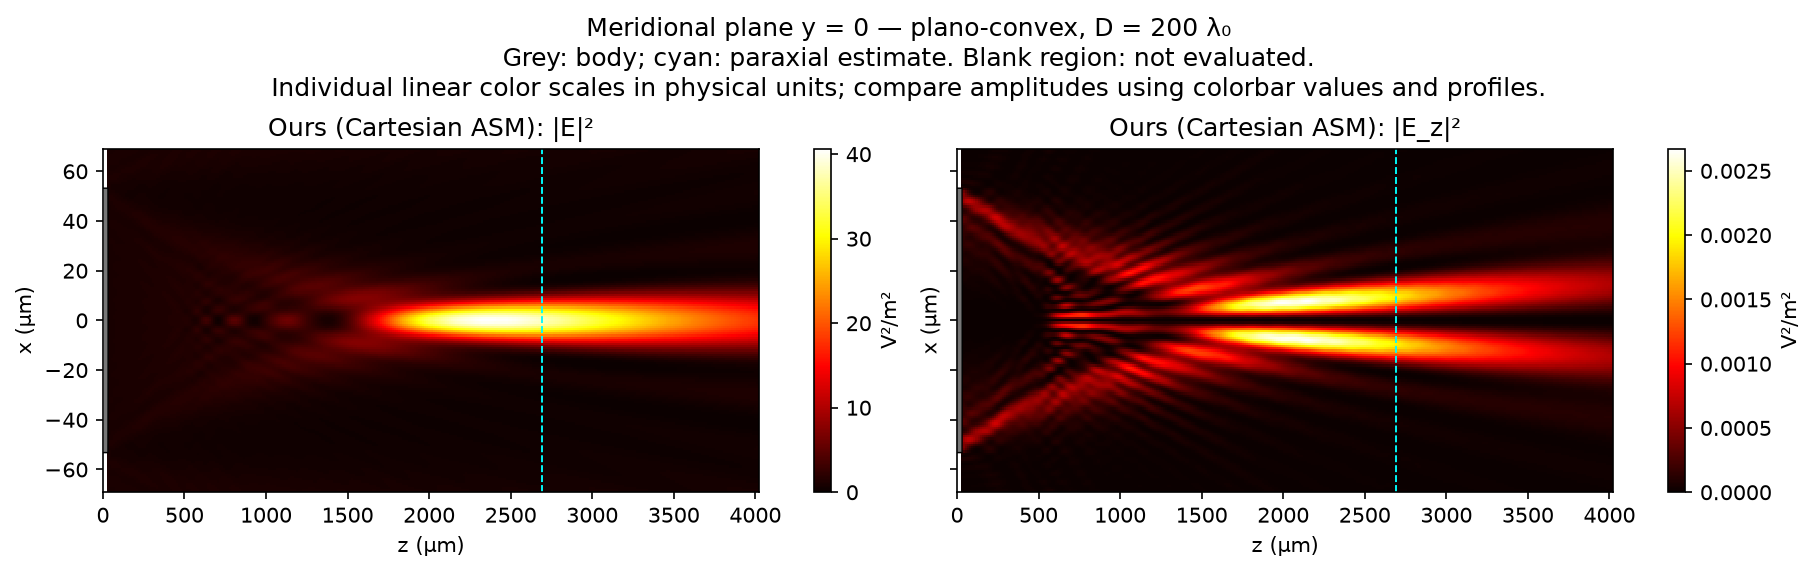

**Common detector plane:** z = 2351 µm (sampled on-axis maximum of Ours). Every method is evaluated at this identical plane; no independent peak alignment is applied. For wavelength-scale objects an axial maximum does not by itself establish a geometrical focus.

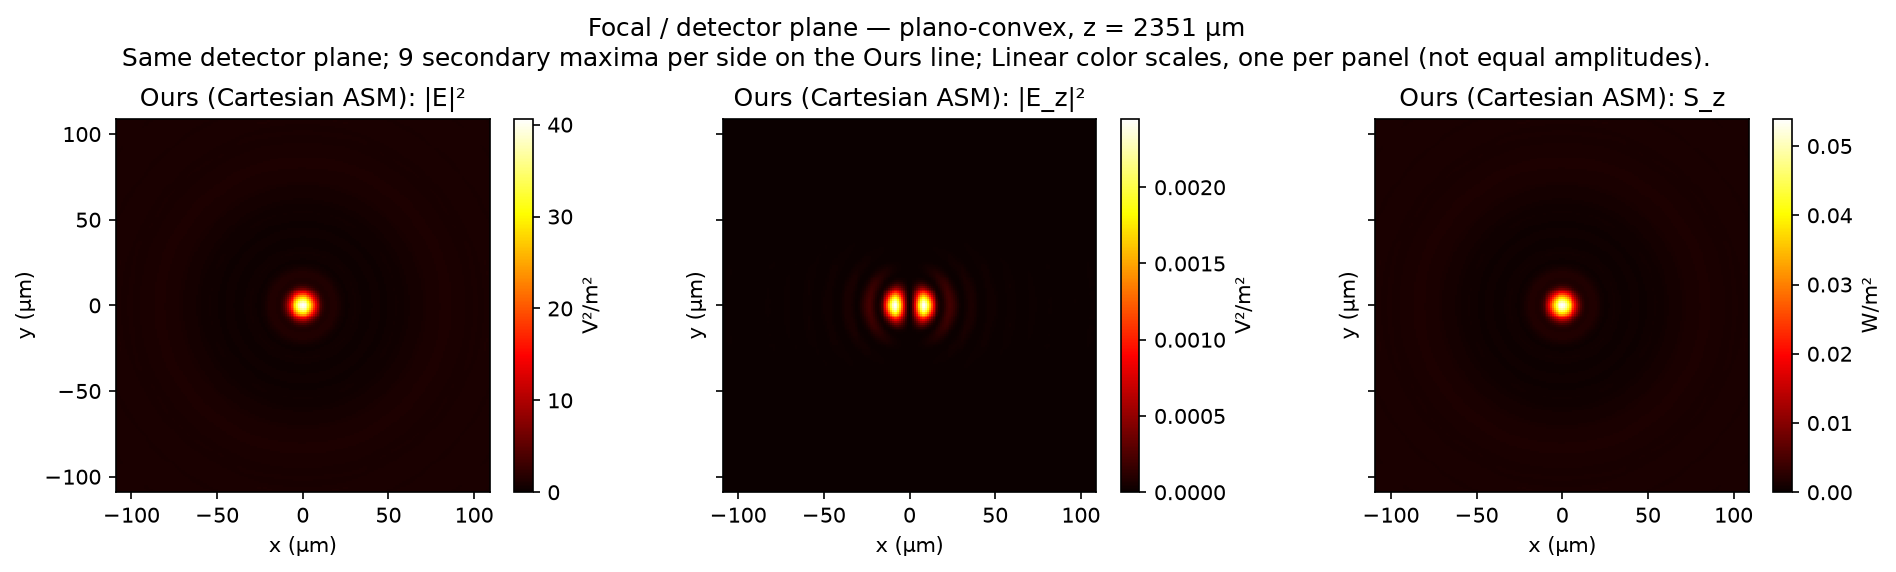

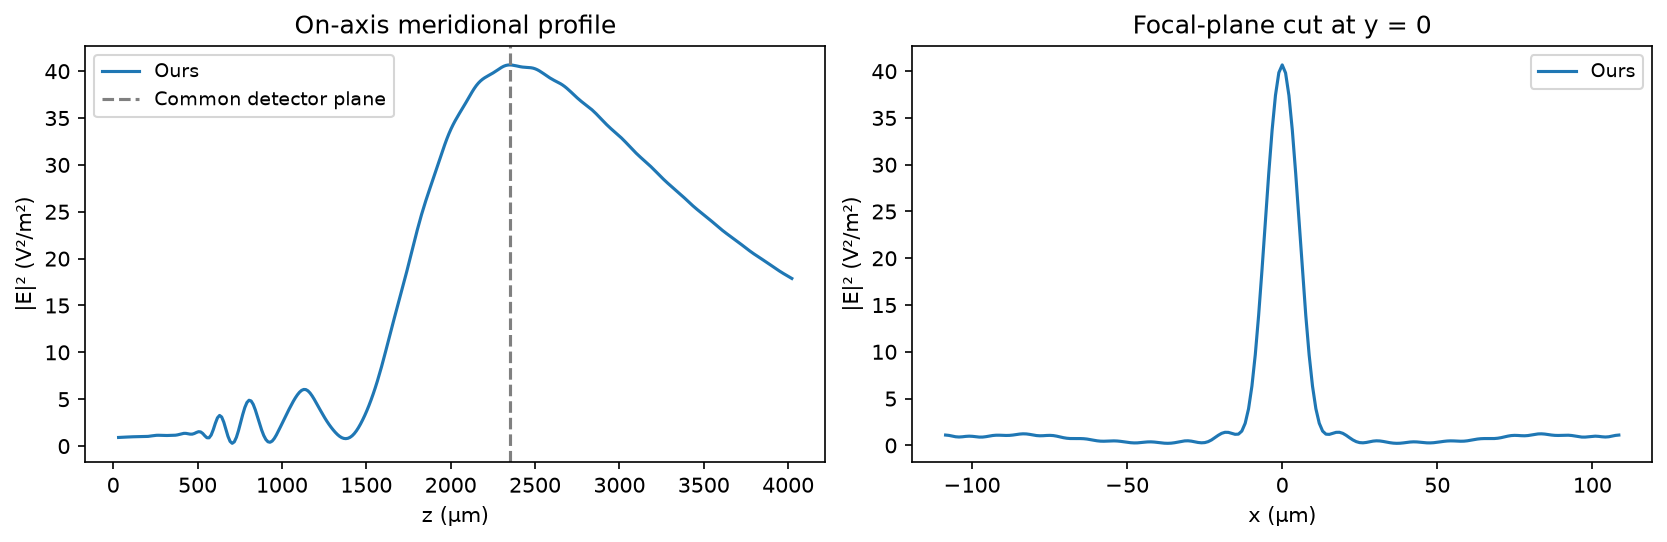

**FEM status:** no volume solution was run at this size; no FEM focal map is available.

In [10]:
macro_groups = {}
for shape in ("plano-convex",):
    group = []
    for diameter in (20, 200, 2000):
        print(f"Weak {shape}, D/λ₀={diameter}", flush=True)
        c = compare_case(
            shape,
            diameter,
            grids=(256, 384),
            window_apertures=24,
            run_bem=False,
            run_fem=False,
            weak=True,
        )
        group.append(c)
        cases.append(c)
    macro_groups[shape] = group
    display(Markdown(f"### {shape} — weak-lens size parameters"))
    report(group)

display(Markdown("### Developed focusing example — our method, D = 200λ₀"))
display(
    Markdown(
        "This weak plano-convex lens shows propagation and a focal spot at optical scale. BEM and FEM were not computed at this size; these plots demonstrate our method, not full-wave agreement."
    )
)
field_view(macro_groups["plano-convex"][1])

## Numerical summary

The summary gives the planar-limit error, small-sphere field gaps and measured execution time. Timings are machine-dependent.

In [11]:
elapsed = perf_counter() - started
small = finest_rows(sphere_cases[:1])
lines = [
    "### Numerical conclusions",
    f"- Our oblique planar limit agrees with Fresnel scattering to **{plane_error:.2e}** relative E error.",
]
for row in small:
    if row.get("field_gap") is not None:
        lines.append(
            f"- Small sphere, **{row['method']}**: E gap to Mie **{100 * row['field_gap']:.2f}%**. {row['status']}."
        )
lines += [
    "- BEM refinement gives a useful independent field comparison; the displayed pointwise boundary residuals remain a stricter limit than selected observation errors.",
    "- FEM is functioning as an independent vector solver. Its coarse first-order meshes need further refinement before use as a precision reference; exact tangential-E continuity alone does not certify it.",
    "- Our sphere result uses a central forward chart; its difference from Mie is not a like-for-like full-sphere discretization error. Lens differences retain approximate sidewall coupling and omitted returning-wave effects.",
    "- The macroscopic rows measure our operational method only. They provide no full-wave validation of macroscopic lenses.",
    "- The displayed fields use Cartesian ASM with variable-height surface transport and a numerical Q inverse.",
    "- The window study above compares complex E and Ez at identical physical points. Its widest run is a numerical control, not an exact reference.",
    f"- Total notebook elapsed time: **{elapsed:.1f} s**.",
]
display(Markdown("\n".join(lines)))

### Numerical conclusions
- Our oblique planar limit agrees with Fresnel scattering to **3.96e-15** relative E error.
- Small sphere, **Ours**: E gap to Mie **98.68%**. central chart behind a 0.45R stop; the reference is the whole sphere.
- Small sphere, **BEM**: E gap to Mie **0.44%**. refinement required.
- Small sphere, **FEM**: E gap to Mie **19.79%**. refinement required.
- Small sphere, **Mie**: E gap to Mie **0.00%**. analytic multipole reference.
- BEM refinement gives a useful independent field comparison; the displayed pointwise boundary residuals remain a stricter limit than selected observation errors.
- FEM is functioning as an independent vector solver. Its coarse first-order meshes need further refinement before use as a precision reference; exact tangential-E continuity alone does not certify it.
- Our sphere result uses a central forward chart; its difference from Mie is not a like-for-like full-sphere discretization error. Lens differences retain approximate sidewall coupling and omitted returning-wave effects.
- The macroscopic rows measure our operational method only. They provide no full-wave validation of macroscopic lenses.
- The displayed fields use Cartesian ASM with variable-height surface transport and a numerical Q inverse.
- The window study above compares complex E and Ez at identical physical points. Its widest run is a numerical control, not an exact reference.
- Total notebook elapsed time: **259.8 s**.

## Conclusions

- The planar-interface comparison agrees with Fresnel scattering to the reported numerical precision. Small exterior Maxwell residuals establish consistency in the homogeneous observation region, but do not determine interface accuracy.
- BEM agrees more closely with Mie than the displayed coarse FEM solutions for the small sphere. Its mesh changes and boundary residuals remain relevant to the precision of the lens comparisons.
- The main method produces central focal spots and paired longitudinal lobes. Its absolute amplitudes differ substantially from the full-body references in the small-object cases.
- Wider FFT windows reduce the repeated downstream structure in the lens fields. The fixed-spacing window tables quantify this sensitivity separately from grid refinement.
- The sphere calculation follows a central chart behind a 0.45R stop; the reference describes the whole sphere. Conditional rim coupling applies to eligible lenses; returning waves are absent from the main path.
- The macroscopic examples show focusing for progressively weaker lenses. Their tables contain no independent full-wave reference at those sizes.
